# Synthetic full experiment

Gaussian HMM, three-component GMM HMM, and Gaussian-base and Student-t-base
spline-flow HMMs on the full **100-replicate × 100-initialization** experiment.

## tl;dr

- Two regimes, four generating families, and 100 dataset replicates give
  **800 dataset conditions**. All four model types were trained again.
- Each dataset/model uses **100 fitted initializations**; the highest training
  likelihood selects one winner. The run contains **320,000 fits**, **3,200
  selected models**, and **12,800 clean/noisy evaluation rows**.
- All evaluation and density-recovery measurements are complete. The 11 GMM
  normalization-check failures were repaired from saved checkpoints.
- This notebook reads the completed results and saved models. **Run All**
  regenerates tables and plots without training, tuning, or rerunning sequence
  evaluations. VPN and OrbStack are unnecessary.

This follows the presentation of `nf_spine_synthetic_experiments.ipynb`, using
the full run under `cluster_runs/hmm_100x100/comparison`.

## Context & Methods

### Setup and display choices

Use the project's `.venv` Python kernel. Open this notebook from either the
project root or `notebooks/`. Change the example settings below to inspect a
different saved family or replicate, then rerun the relevant plotting cells.
Aggregate comparisons always use the full 100 dataset replicates.

In [1]:
import json
import sys
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from threadpoolctl import threadpool_limits

project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "src/flexible_emission_hmm").is_dir()
)
for path in (project_root / "scripts", project_root / "src",
             project_root / "notebooks"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import report_hmm_cluster as reporting

implementation = reporting.runtime()
experiment = implementation.experiment
get_ipython().run_line_magic("matplotlib", "inline")
torch.set_num_threads(1)
numerical_threads = threadpool_limits(limits=1)

RUN_DIRECTORY = project_root / "cluster_runs/hmm_100x100"
COMPARISON_DIRECTORY = RUN_DIRECTORY / "comparison"
OUTPUT_DIRECTORY = COMPARISON_DIRECTORY / "synthetic_full_experiment"
REGIMES = ("mean", "volatility")
EXAMPLE_FAMILIES = ("Gaussian", "Student-t", "Trimodal", "Skewed Gamma")
EMISSION_DENSITY_REPLICATE = 0
DECODED_PATH_FAMILY = "Trimodal"
DECODED_PATH_REPLICATE = 0
DECODED_CONDITIONS = ("clean", "noise_0.5")
DECODED_POINTS = 5000
HISTORY_REPLICATE = 0
INITIALIZATION_REGIME = "volatility"
INITIALIZATION_FAMILY = "Trimodal"
INITIALIZATION_REPLICATE = 0
BOOTSTRAP_SAMPLES = 2000
BOOTSTRAP_SEED = 42

FIGURE_DIRECTORY = OUTPUT_DIRECTORY / "figures"
TABLE_DIRECTORY = OUTPUT_DIRECTORY / "tables"
FIGURE_DIRECTORY.mkdir(parents=True, exist_ok=True)
TABLE_DIRECTORY.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.grid": False, "figure.dpi": 100})
pd.set_option("display.max_columns", 16)
pd.set_option("display.max_rows", 36)
figure_files, table_files = [], []

In [2]:
def show_and_save(fig, name):
    """Display a figure and export it with a shared, readable legend."""
    handles, labels = [], []
    for axis in fig.axes:
        if name.endswith("paired_model_differences"):
            axis.xaxis.set_major_locator(MaxNLocator(nbins=3))
            axis.ticklabel_format(axis="x", style="sci",
                                  scilimits=(-3, 4), useOffset=False)
        legend = axis.get_legend()
        if legend is None:
            continue
        current_handles, current_labels = axis.get_legend_handles_labels()
        for handle, label in zip(current_handles, current_labels):
            if label not in labels:
                handles.append(handle)
                labels.append(label)
        legend.remove()
    if labels:
        fig.legend(handles, labels, loc="outside lower center",
                   ncol=min(4, len(labels)), fontsize=9, frameon=False)
    filename = name.replace(" ", "_") + ".png"
    fig.savefig(FIGURE_DIRECTORY / filename, dpi=160, bbox_inches="tight")
    display(fig)
    plt.close(fig)
    figure_files.append(filename)

def save_table(frame, name, *, index=True):
    """Export a derived table without changing the evaluation inputs."""
    filename = name + ".csv"
    frame.to_csv(TABLE_DIRECTORY / filename, index=index)
    table_files.append(filename)
    return frame

def metric_plot(data, regime, metrics, name, *, noise=False):
    """Plot complete four-model groups using the original experiment style."""
    paired = experiment.metric_groups(data, metrics)
    if paired[paired.regime == regime].empty:
        raise ValueError(f"No complete metric groups for {regime}: {metrics}")
    show_and_save(experiment.plot_metrics(paired, regime, metrics, noise=noise), name)

### Data sources and completeness checks

The plan defines the training budget, selected settings, and dataset sources.
The comparison CSVs contain the collected evaluations. These checks reject
missing conditions, duplicate evaluations, incomplete restart budgets, and
unresolved density diagnostics before generating comparisons.

In [3]:
plan_path = RUN_DIRECTORY / "plan.json"
plan = reporting.read_json(plan_path)
manifest = reporting.read_json(COMPARISON_DIRECTORY / "manifest.json")
assert manifest["plan_id"] == plan["id"], "Plan identity mismatch"
sources = implementation.load_sources(project_root, plan["sources"])
names = ("results", "attempts", "per_state", "confusion", "parameters", "coverage")
run = {
    name: pd.read_csv(COMPARISON_DIRECTORY / f"{name}.csv",
                      float_precision="round_trip")
    for name in names
}
results, attempts = run["results"], run["attempts"]
identity_columns = experiment.KEYS + ["model", "condition"]
expected = {
    tuple(group[key] for key in experiment.KEYS) + (group["model"], condition)
    for group in plan["groups"]
    for condition in ["clean"] + [
        f"noise_{level}" for level in sources[group["regime"]].noise_levels
    ]
}
assert not results.duplicated(identity_columns).any()
assert set(results[identity_columns].itertuples(index=False, name=None)) == expected
assert results.evaluation_status.eq("ok").all(), "Inspect failed evaluations"
assert results.recovery_status.eq("ok").all(), "Finish density diagnostic repairs"
density_metrics = ["emission_kl", "mean_rmse", "variance_rmse"]
assert np.isfinite(results[density_metrics].to_numpy()).all()
attempt_keys = experiment.KEYS + ["model"]
assert not attempts.duplicated(attempt_keys + ["start"]).any()
restart_counts = attempts.groupby(attempt_keys).size()
assert len(restart_counts) == len(plan["groups"])
assert restart_counts.eq(plan["n_starts"]).all()
assert set(attempts.start.unique()) == set(range(plan["n_starts"]))
selected_attempts = attempts[attempts.selected.isin([True, "True", 1])].copy()
assert selected_attempts.groupby(attempt_keys).size().eq(1).all()
assert len(selected_attempts) == len(plan["groups"])
best_likelihoods = attempts[attempts.status.eq("ok")].groupby(attempt_keys).train_ll.max()
chosen_likelihoods = selected_attempts.set_index(attempt_keys).train_ll
pd.testing.assert_series_equal(chosen_likelihoods.sort_index(),
                               best_likelihoods.sort_index())
clean = experiment.complete_groups(results, ["clean"])
robust = experiment.complete_groups(results)
assert len(clean) == len(plan["groups"])
assert len(robust) == len(results)
saved = reporting.SavedRun(COMPARISON_DIRECTORY, plan, implementation)
input_hashes = {
    f"{name}.csv": reporting.digest(COMPARISON_DIRECTORY / f"{name}.csv")
    for name in names
}
input_hashes["manifest.json"] = reporting.digest(COMPARISON_DIRECTORY / "manifest.json")
print(f"Validated {len(results):,} evaluation rows and {len(attempts):,} starts.")
print(f"Plan: {plan['id']}")
print(f"Exports: {OUTPUT_DIRECTORY}")

Validated 12,800 evaluation rows and 320,000 starts.
Plan: b31c5e30e63f1b44628e81a0a911eafb48a6fbcef2cef017717f56e3b11001d3
Exports: /Users/leoyang/Desktop/School/CSCD94/cluster_runs/hmm_100x100/comparison/synthetic_full_experiment


### Experimental design and metric definitions

Both regimes use three states and persistence **0.995**. Mean-separated data
have means $(-2,0,2)$ and variance 1. Volatility-only data have zero means and
standard deviations $(1,2,4)$. Every dataset has 20,000 training observations
and an independent 5,000-observation test sequence. Replicates 0–9 preserve the
original data; replicates 10–99 use the frozen extension's deterministic seeds.

Gaussian, three-component GMM, and both flow models were retrained with 100
starts per dataset/model. The selected start maximizes **training** likelihood;
test results do not select the winner. Flow hyperparameters reuse the saved
training-only validation selections; this notebook does not retune them.

For the observation-to-base flow $f_k$:

$$
\log p_k(x)=\log p_{\mathrm{base}}(f_k(x))+\log|f'_k(x)|.
$$

The Student-t flow base uses fixed $\nu=5$ and unit variance, with scale
$\sqrt{(\nu-2)/\nu}$. State labels are aligned using training truth to remove
label permutation before scoring this synthetic benchmark.

### Key assumptions

- Comparisons pair models within the same regime, family, size, and replicate.
  The 100 starts are optimization attempts, **not** 100 independent test datasets.
- Metric panels show the replicate mean ± **one sample SD**. Paired differences
  show **95% percentile bootstrap intervals** from independent dataset replicates.
- Test NLL is per observation and should be compared within a regime/family.
  Emission KL is $\mathrm{KL}(p_{\rm true}\|p_{\rm fitted})$, equally averaged
  across aligned states, against the clean generating distribution.
- Only training size 20,000 is present. Training-size panels therefore show one
  point per model, rather than a learning curve across sizes.

In [4]:
design = pd.DataFrame([
    {"regime": regime, "families": len(source.families),
     "dataset replicates": source.settings["n_replicates"],
     "starts / model / dataset": plan["n_starts"],
     "training observations": max(source.settings["train_sizes"]),
     "test observations": source.settings["n_test"],
     "persistence": plan["persistence"]}
    for regime, source in sources.items()
])
display(save_table(design, "experimental_design", index=False))
settings_table = pd.json_normalize(plan["selections"])
setting_columns = [column for column in [
    "regime", "family", "settings.base_distribution", "settings.count_bins",
    "settings.num_layers", "settings.m_step_steps", "settings.batch_size",
    "settings.learning_rate", "settings.convergence_patience", "validation_nll"
] if column in settings_table]
display(save_table(settings_table[setting_columns], "selected_flow_settings", index=False))

,regime,families,dataset replicates,starts / model / dataset,training observations,test observations,persistence
0,mean,4,100,100,20000,5000,0.995
1,volatility,4,100,100,20000,5000,0.995


,regime,family,settings.base_distribution,settings.count_bins,settings.num_layers,settings.m_step_steps,settings.batch_size,settings.learning_rate,settings.convergence_patience,validation_nll
0,mean,Gaussian,normal,4,1,20,2048,0.001,5,1.463144
1,mean,Student-t,normal,8,3,20,2048,0.001,5,1.092132
2,mean,Trimodal,normal,8,3,20,2048,0.001,5,1.177735
3,mean,Skewed Gamma,normal,8,2,20,2048,0.001,5,1.368160
4,volatility,Gaussian,normal,4,1,20,2048,0.001,5,2.200688
5,volatility,Student-t,normal,4,3,20,2048,0.001,5,1.802010
6,volatility,Trimodal,normal,16,1,20,2048,0.001,5,1.949295
7,volatility,Skewed Gamma,normal,8,1,20,2048,0.001,5,2.085831
8,mean,Gaussian,student_t,4,1,20,2048,0.001,5,1.465660
9,mean,Student-t,student_t,4,2,20,2048,0.001,5,1.078477


## Data

### Coverage and repaired diagnostics

Each regime/family/model has 100 dataset replicates and four test conditions:
clean, then final measurement-noise SDs of 0.1, 0.25, and 0.5 times training SD.
Gaussian and GMM results are new fits, so old baseline-replay checks do not apply.

In [5]:
coverage = results.groupby(["regime", "family", "model"]).agg(
    dataset_replicates=("replicate", "nunique"),
    test_conditions=("condition", "nunique"), evaluation_rows=("condition", "size")
)
display(save_table(coverage, "evaluation_coverage"))
repair_path = COMPARISON_DIRECTORY / "density_repair/report.json"
repair_record = reporting.read_json(repair_path) if repair_path.exists() else None
if repair_record:
    assert repair_record["status"] == "complete"
    repaired = pd.json_normalize(repair_record["repairs"])
    display(Markdown(
        f"**Density repair:** {len(repaired)} GMM winners repaired from saved "
        "checkpoints; analytic mixture moments and component-resolved KL. "
        "Prediction metrics and checkpoints were preserved."
    ))
    display(save_table(repaired[["regime", "family", "replicate", "model",
                                 "selected_start", "metrics.emission_kl",
                                 "metrics.kl_quad_error_max"]],
                       "repaired_density_diagnostics", index=False))
diagnostic_columns = ["regime", "family", "model", "condition", "recovery_status"]
diagnostics = results.groupby(diagnostic_columns).size().rename("rows").reset_index()
save_table(diagnostics, "recovery_coverage", index=False)

dataset_replicates  \
regime     family       model                                       
mean       Gaussian     GMM HMM                               100   
                        Gaussian HMM                          100   
                        RQ-NSF Gaussian base                  100   
                        RQ-NSF Student-t base                 100   
           Skewed Gamma GMM HMM                               100   
                        Gaussian HMM                          100   
                        RQ-NSF Gaussian base                  100   
                        RQ-NSF Student-t base                 100   
           Student-t    GMM HMM                               100   
                        Gaussian HMM                          100   
                        RQ-NSF Gaussian base                  100   
                        RQ-NSF Student-t base                 100   
           Trimodal     GMM HMM                               100   
                        Gaussian HMM                          100   
                        RQ-NSF Gaussian base                  100   
                        RQ-NSF Student-t base                 100   
volatility Gaussian     GMM HMM                               100   
                        Gaussian HMM                          100   
                        RQ-NSF Gaussian base                  100   
                        RQ-NSF Student-t base                 100   
           Skewed Gamma GMM HMM                               100   
                        Gaussian HMM                          100   
                        RQ-NSF Gaussian base                  100   
                        RQ-NSF Student-t base                 100   
           Student-t    GMM HMM                               100   
                        Gaussian HMM                          100   
                        RQ-NSF Gaussian base                  100   
                        RQ-NSF Student-t base                 100   
           Trimodal     GMM HMM                               100   
                        Gaussian HMM                          100   
                        RQ-NSF Gaussian base                  100   
                        RQ-NSF Student-t base                 100   

                                               test_conditions  \
regime     family       model                                    
mean       Gaussian     GMM HMM                              4   
                        Gaussian HMM                         4   
                        RQ-NSF Gaussian base                 4   
                        RQ-NSF Student-t base                4   
           Skewed Gamma GMM HMM                              4   
                        Gaussian HMM                         4   
                        RQ-NSF Gaussian base                 4   
                        RQ-NSF Student-t base                4   
           Student-t    GMM HMM                              4   
                        Gaussian HMM                         4   
                        RQ-NSF Gaussian base                 4   
                        RQ-NSF Student-t base                4   
           Trimodal     GMM HMM                              4   
                        Gaussian HMM                         4   
                        RQ-NSF Gaussian base                 4   
                        RQ-NSF Student-t base                4   
volatility Gaussian     GMM HMM                              4   
                        Gaussian HMM                         4   
                        RQ-NSF Gaussian base                 4   
                        RQ-NSF Student-t base                4   
           Skewed Gamma GMM HMM                              4   
                        Gaussian HMM                         4   
                        RQ-NSF Gaussian base                 4   
                        RQ-NSF Student-t base     

**Density repair:** 11 GMM winners repaired from saved checkpoints; analytic mixture moments and component-resolved KL. Prediction metrics and checkpoints were preserved.

,regime,family,replicate,model,selected_start,metrics.emission_kl,metrics.kl_quad_error_max
0,mean,Gaussian,42,GMM HMM,66,0.000311,1.026831e-13
1,mean,Gaussian,61,GMM HMM,24,0.000398,1.056370e-13
2,mean,Gaussian,75,GMM HMM,68,0.000423,3.098334e-12
3,volatility,Gaussian,20,GMM HMM,93,0.000362,2.599279e-16
4,volatility,Gaussian,31,GMM HMM,76,0.000424,3.872203e-13
5,volatility,Gaussian,32,GMM HMM,60,0.000264,4.293726e-11
6,volatility,Gaussian,33,GMM HMM,93,0.000176,1.492161e-15
7,volatility,Gaussian,50,GMM HMM,19,0.000851,7.831461e-12
8,volatility,Gaussian,68,GMM HMM,35,0.000341,5.427244e-13
9,volatility,Gaussian,97,GMM HMM,2,0.000572,9.852645e-13


,regime,family,model,condition,recovery_status,rows
0,mean,Gaussian,GMM HMM,clean,ok,100
1,mean,Gaussian,GMM HMM,noise_0.1,ok,100
2,mean,Gaussian,GMM HMM,noise_0.25,ok,100
3,mean,Gaussian,GMM HMM,noise_0.5,ok,100
4,mean,Gaussian,Gaussian HMM,clean,ok,100
...,...,...,...,...,...,...
123,volatility,Trimodal,RQ-NSF Gaussian base,noise_0.5,ok,100
124,volatility,Trimodal,RQ-NSF Student-t base,clean,ok,100
125,volatility,Trimodal,RQ-NSF Student-t base,noise_0.1,ok,100
126,volatility,Trimodal,RQ-NSF Student-t base,noise_0.25,ok,100


## Results

### Clean-test summary

Values below are means across all 100 dataset replicates. The following plots
retain sample SD, and paired-difference panels retain uncertainty in model
comparisons. No model is selected using these test summaries.

In [6]:
summary_metrics = ["aligned_accuracy", "f1_macro", "test_nll", "emission_kl",
                   "mean_rmse", "variance_rmse", "transition_rmse", "switch_f1"]
group_columns = ["regime", "family", "n_train", "model"]
clean_summary = clean.groupby(group_columns)[summary_metrics].agg(["mean", "std", "count"])
save_table(clean_summary, "clean_metric_summary")
display(clean.groupby(group_columns)[summary_metrics].mean().round(5))

aligned_accuracy  \
regime     family       n_train model                                     
mean       Gaussian     20000   GMM HMM                         0.99755   
                                Gaussian HMM                    0.99752   
                                RQ-NSF Gaussian base            0.99756   
                                RQ-NSF Student-t base           0.99753   
           Skewed Gamma 20000   GMM HMM                         0.99842   
                                Gaussian HMM                    0.99701   
                                RQ-NSF Gaussian base            0.99850   
                                RQ-NSF Student-t base           0.99850   
           Student-t    20000   GMM HMM                         0.99895   
                                Gaussian HMM                    0.97909   
                                RQ-NSF Gaussian base            0.99883   
                                RQ-NSF Student-t base           0.99901   
           Trimodal     20000   GMM HMM                         0.99849   
                                Gaussian HMM                    0.99732   
                                RQ-NSF Gaussian base            0.99844   
                                RQ-NSF Student-t base           0.99842   
volatility Gaussian     20000   GMM HMM                         0.98335   
                                Gaussian HMM                    0.98327   
                                RQ-NSF Gaussian base            0.98327   
                                RQ-NSF Student-t base           0.98254   
           Skewed Gamma 20000   GMM HMM                         0.98642   
                                Gaussian HMM                    0.96484   
                                RQ-NSF Gaussian base            0.98637   
                                RQ-NSF Student-t base           0.98645   
           Student-t    20000   GMM HMM                         0.96022   
                                Gaussian HMM                    0.59756   
                                RQ-NSF Gaussian base            0.96031   
                                RQ-NSF Student-t base           0.96200   
           Trimodal     20000   GMM HMM                         0.99518   
                                Gaussian HMM                    0.88621   
                                RQ-NSF Gaussian base            0.99506   
                                RQ-NSF Student-t base           0.99485   

                                                       f1_macro  test_nll  \
regime     family       n_train model                                       
mean       Gaussian     20000   GMM HMM                 0.99740   1.45067   
                                Gaussian HMM            0.99737   1.45040   
                                RQ-NSF Gaussian base    0.99741   1.45094   
                                RQ-NSF Student-t base   0.99738   1.45386   
           Skewed Gamma 20000   GMM HMM                 0.99832   1.36924   
                                Gaussian HMM            0.99681   1.45033   
                                RQ-NSF Gaussian base    0.99840   1.36498   
                                RQ-NSF Student-t base   0.99840   1.36667   
           Student-t    20000   GMM HMM                 0.99888   1.08304   
                                Gaussian HMM            0.97720   1.35911   
                                RQ-NSF Gaussian base    0.99874   1.08649   
                                RQ-NSF Student-t base   0.99894   1.07968   
           Trimodal     20000   GMM HMM                 0.99838   1.16057   
                                Gaussian HMM            0.99716   1.45127   
                                RQ-NSF Gaussian base    0.99833   1.16273   
                                RQ-NSF Student-t base   0.99832   1.16899   
volatility Gaussian     20000   GMM HMM                 0.98192   2.12986   
                                Gaussian 

### Classification

Accuracy, macro precision, macro recall, and macro F1: mean ± one sample SD.
Each family uses the same 100 test datasets for all four models.

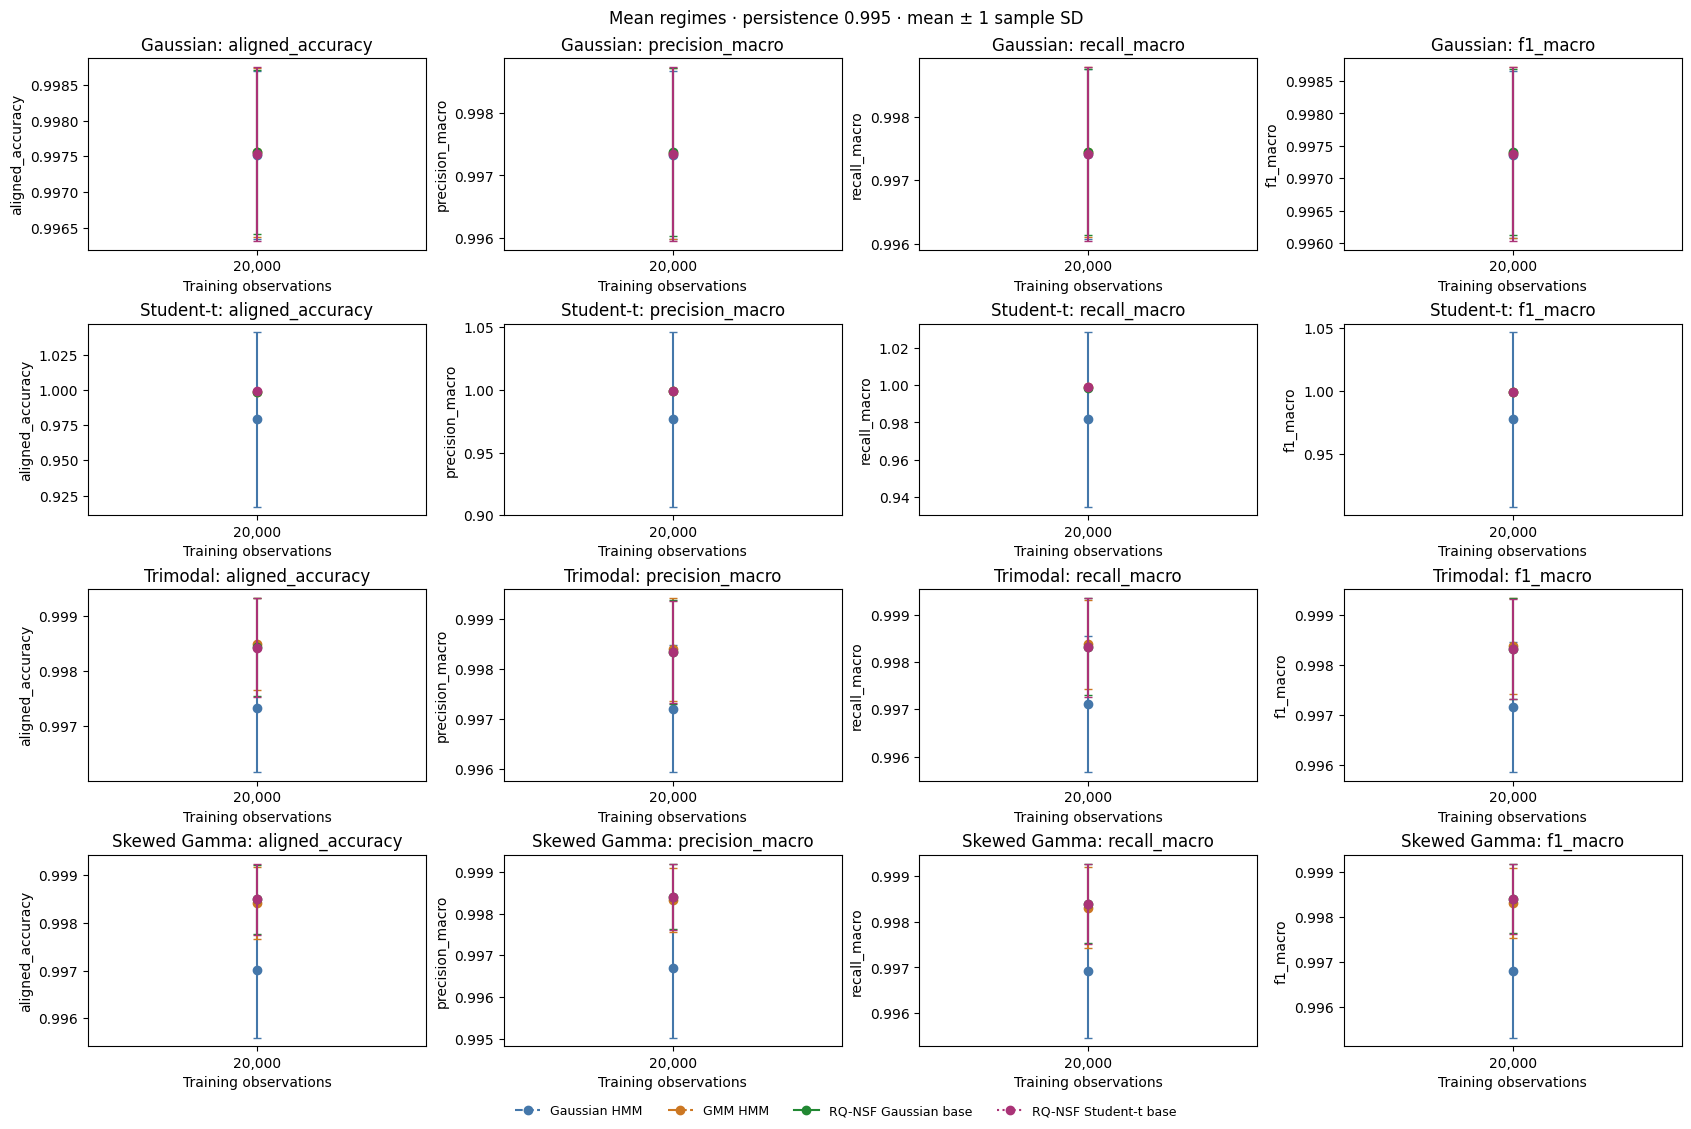

In [7]:
metric_plot(clean, "mean",
            ["aligned_accuracy", "precision_macro", "recall_macro", "f1_macro"],
            "mean_classification")

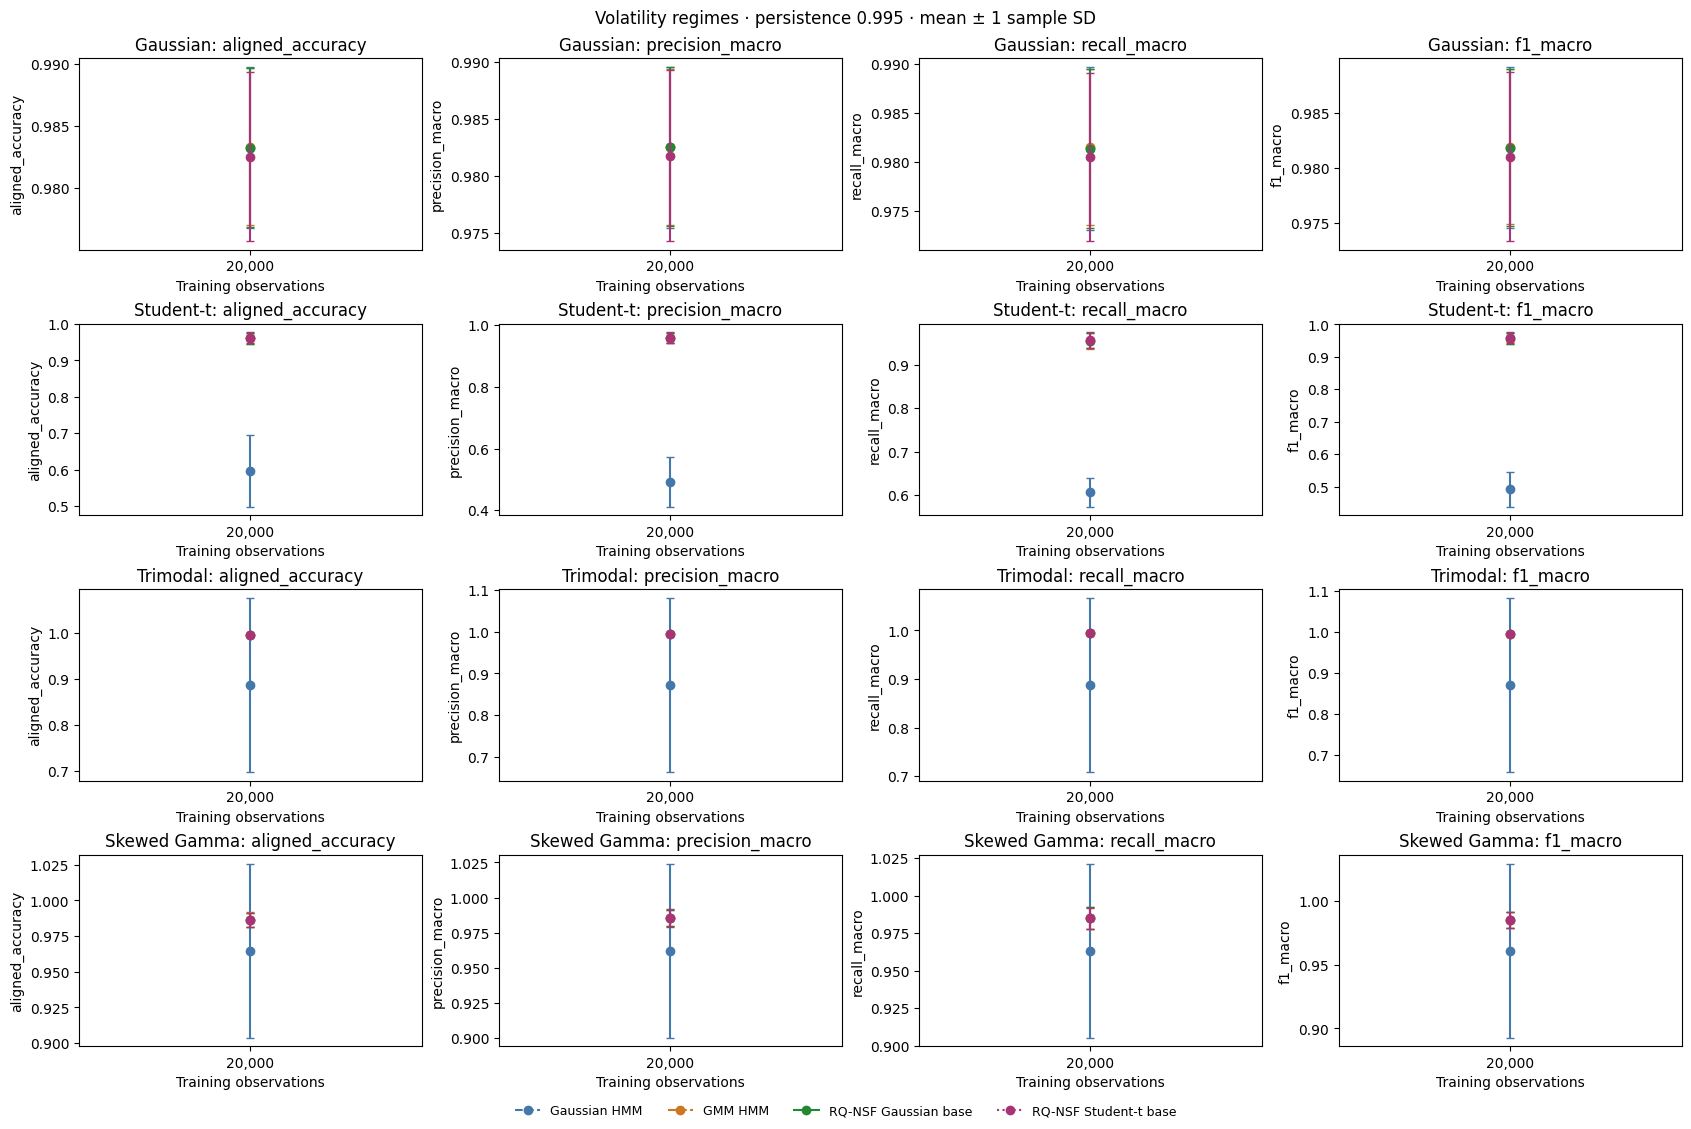

In [8]:
metric_plot(clean, "volatility",
            ["aligned_accuracy", "precision_macro", "recall_macro", "f1_macro"],
            "volatility_classification")

### Density, probability, and transition recovery

Lower test NLL, emission KL, Brier score, and transition RMSE are better.
Recovery diagnostics are complete, including the repaired GMM measurements.

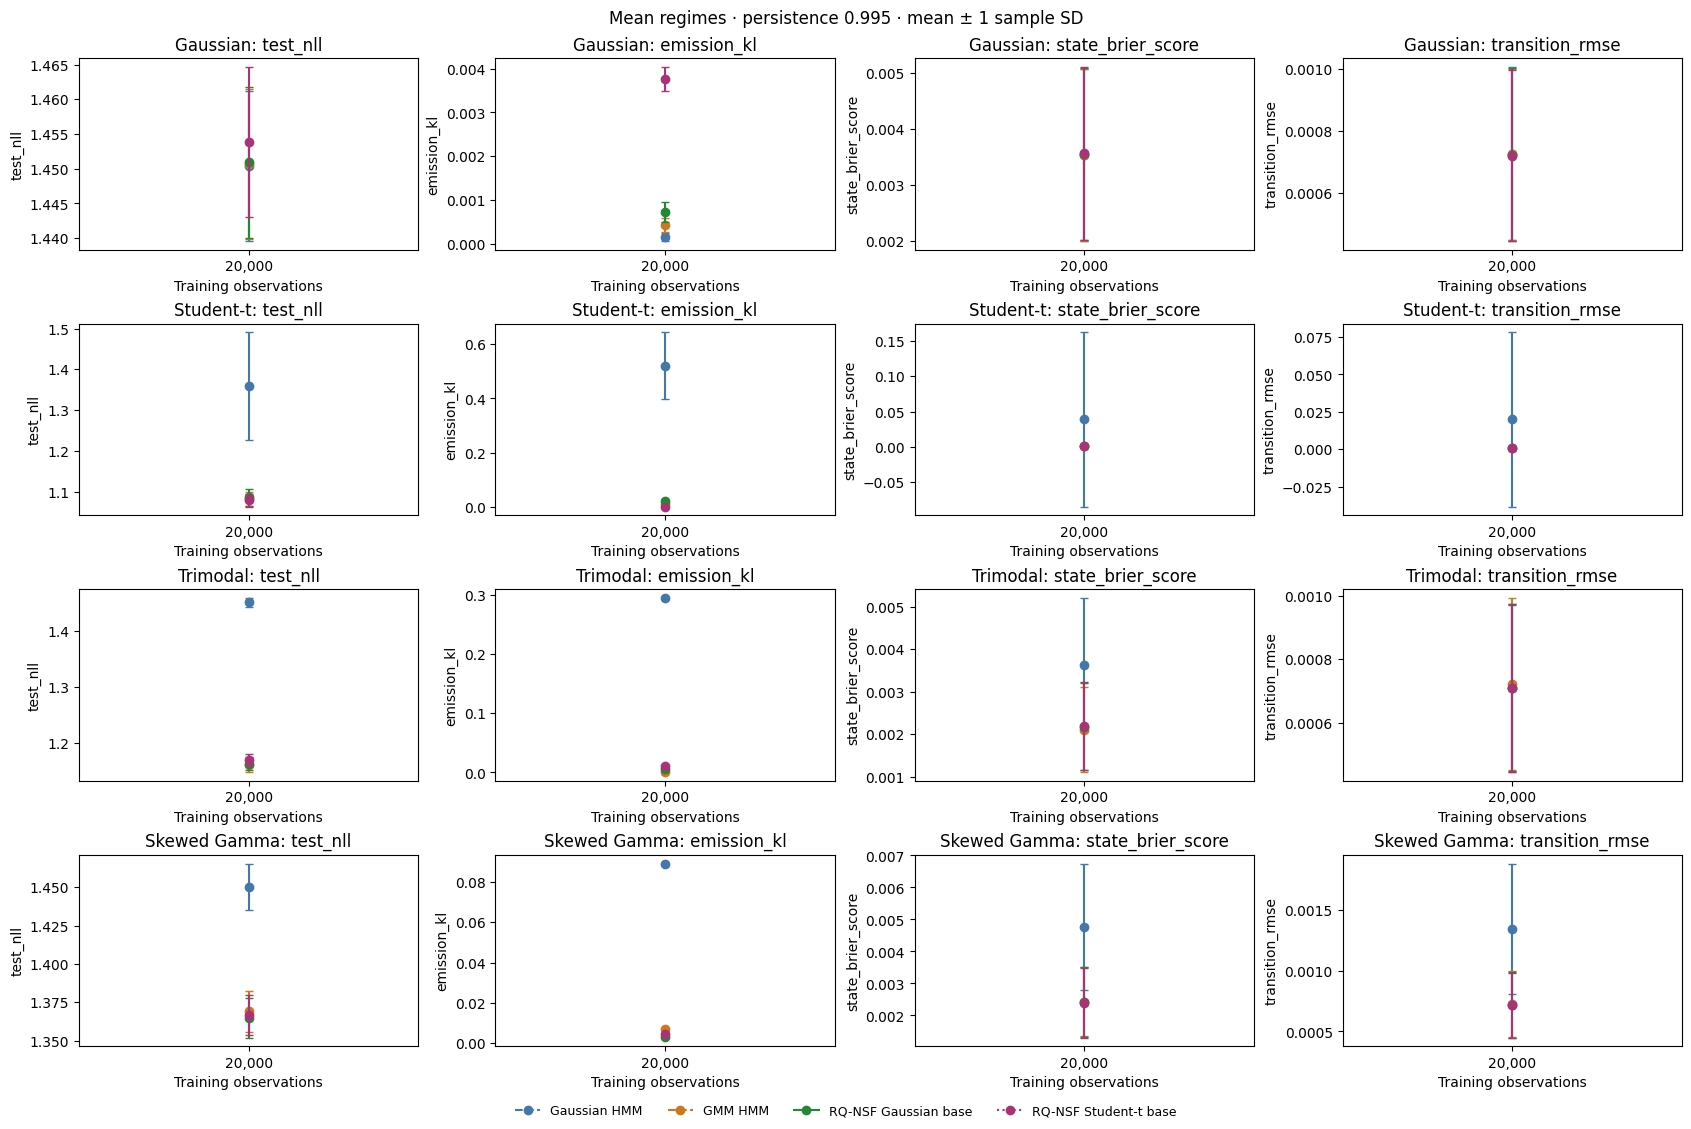

In [9]:
metric_plot(clean, "mean",
            ["test_nll", "emission_kl", "state_brier_score", "transition_rmse"],
            "mean_recovery")

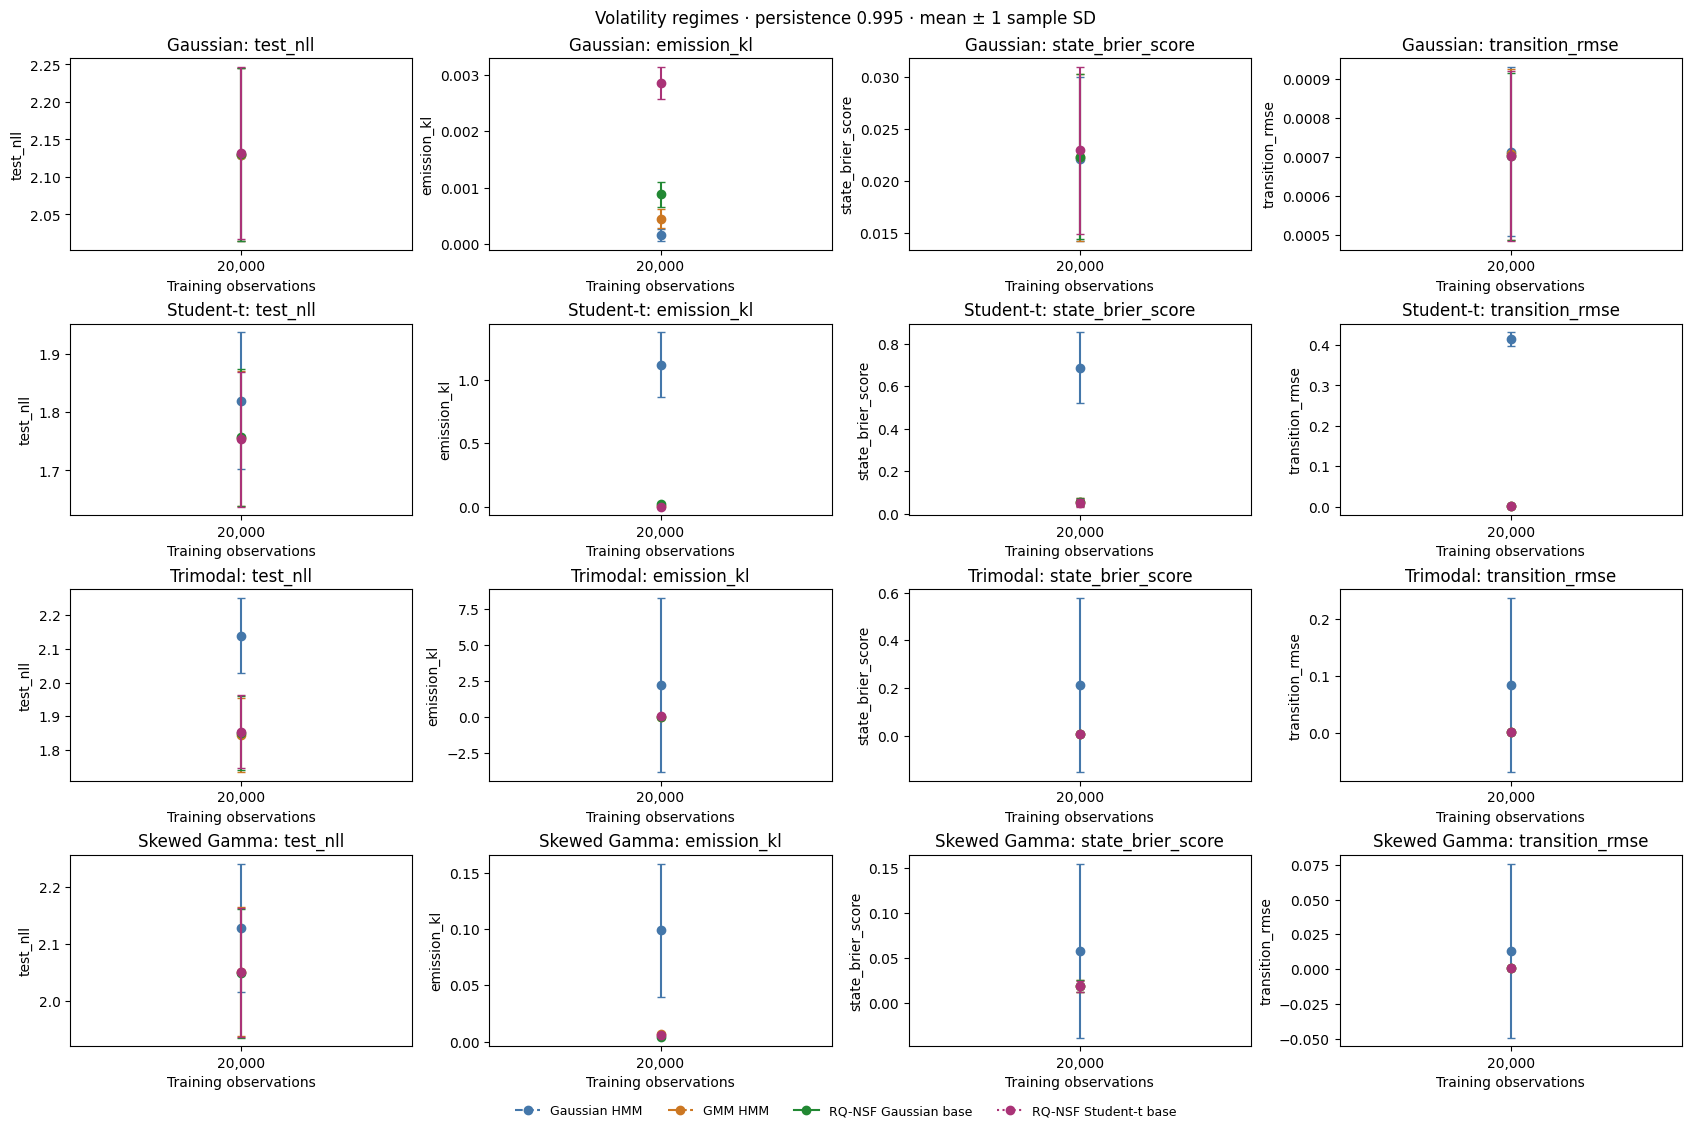

In [10]:
metric_plot(clean, "volatility",
            ["test_nll", "emission_kl", "state_brier_score", "transition_rmse"],
            "volatility_recovery")

### Emission moments, posterior loss, and switches

Lower mean RMSE, variance RMSE, and state log loss are better; higher switch F1
is better. KL and emission moment recovery target the clean emission density,
so those measurements stay the same across test-noise conditions.

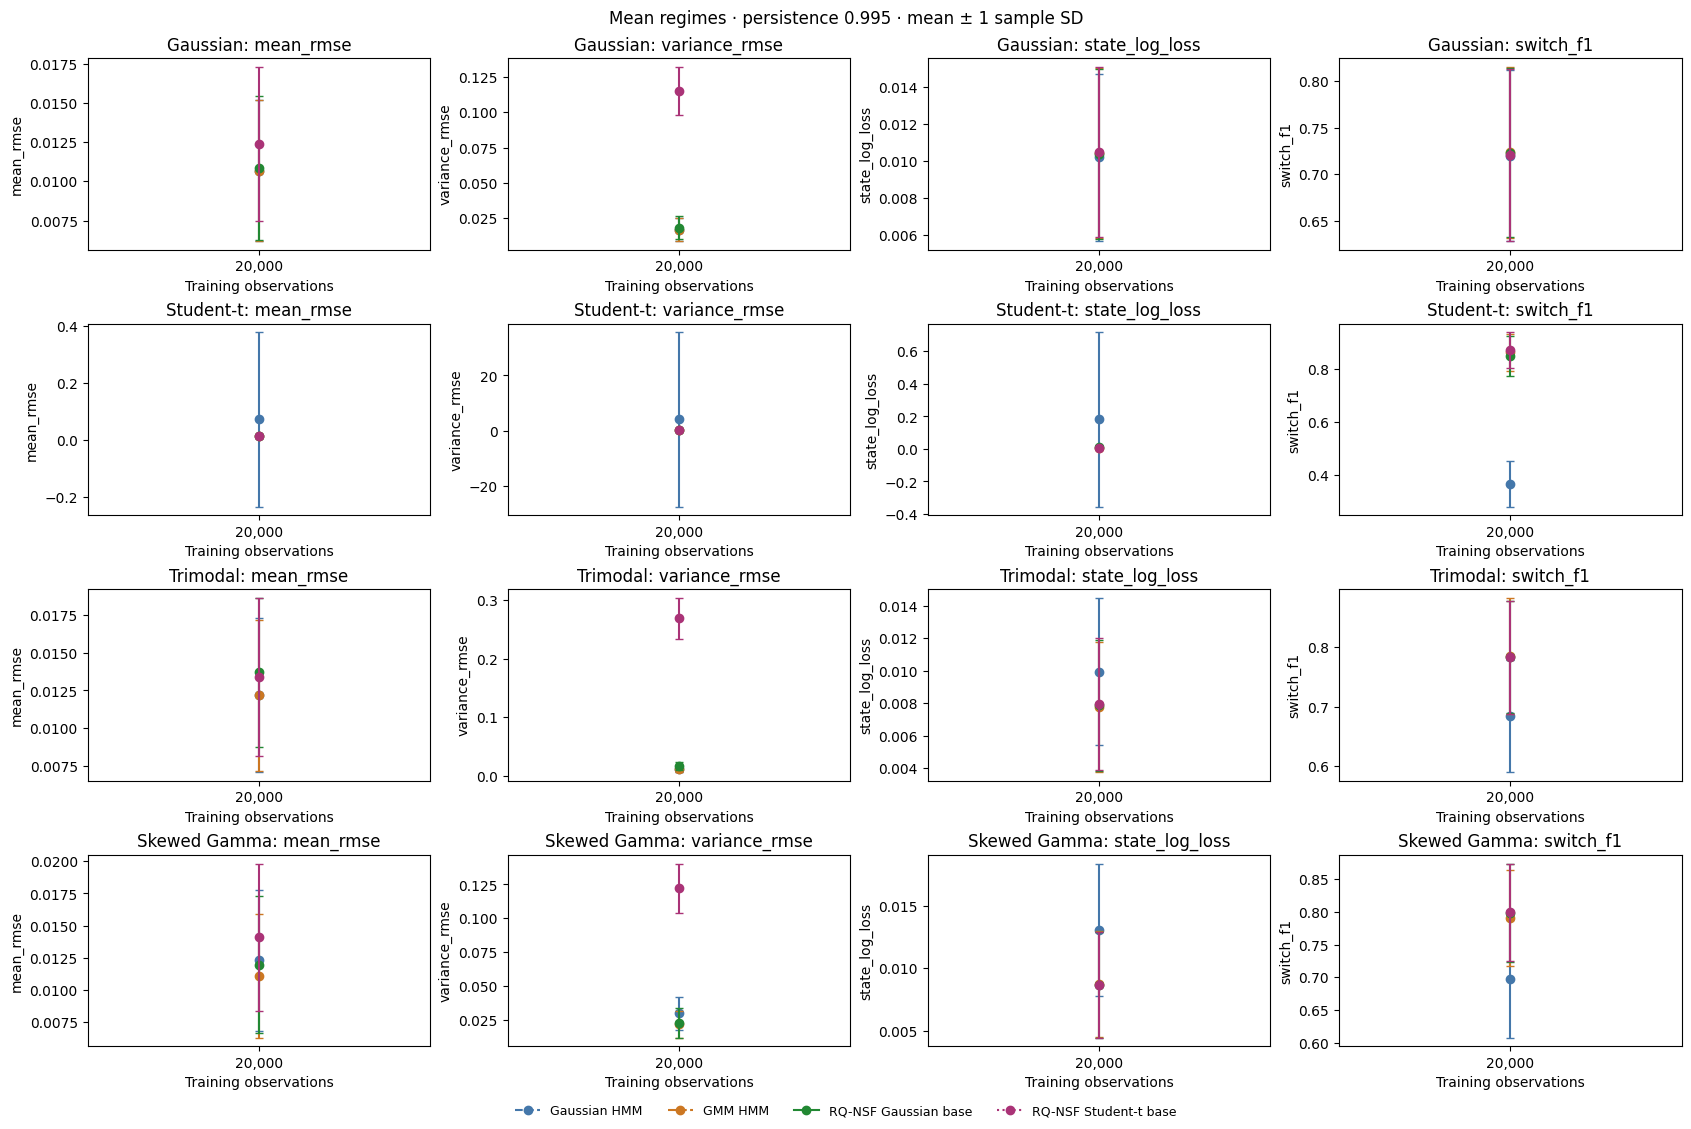

In [11]:
metric_plot(clean, "mean",
            ["mean_rmse", "variance_rmse", "state_log_loss", "switch_f1"],
            "mean_parameters")

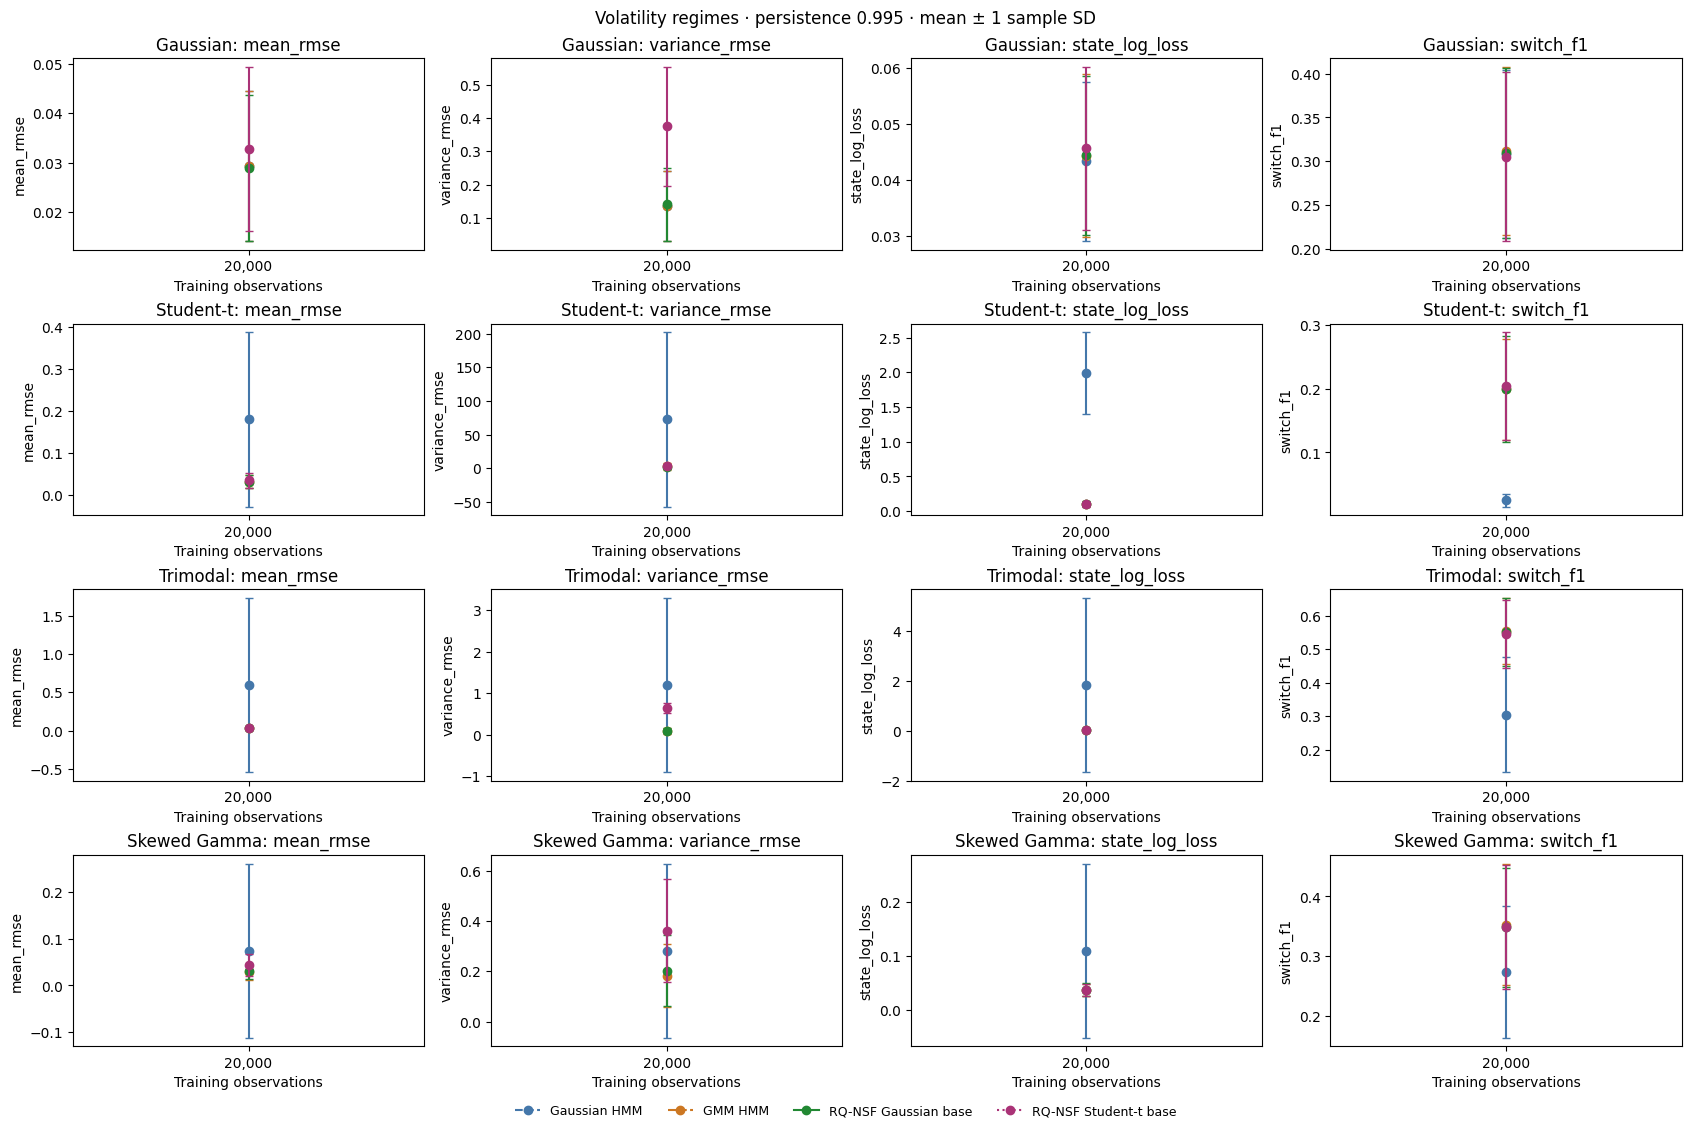

In [12]:
metric_plot(clean, "volatility",
            ["mean_rmse", "variance_rmse", "state_log_loss", "switch_f1"],
            "volatility_parameters")

### All six paired model differences

Subtract **second − first** within each replicate, then average. Intervals
resample dataset replicates 2,000 times with seed 42. Positive differences
favor the second model for F1; negative differences favor it for NLL and KL.
Fitting duration is the sum over its 100 starts, not elapsed cluster wall time.
NSF-N means Gaussian-base flow; NSF-t means Student-t-base flow.

In [13]:
difference_metrics = ["f1_macro", "test_nll", "emission_kl", "total_fit_seconds"]
paired_differences = experiment.paired_differences(
    experiment.metric_groups(clean, difference_metrics), difference_metrics,
    bootstrap_samples=BOOTSTRAP_SAMPLES, seed=BOOTSTRAP_SEED
)
assert paired_differences.n_pairs.eq(plan["n_replicates"]).all()
save_table(paired_differences, "paired_model_differences", index=False)
display(paired_differences.query("metric == 'f1_macro'").round(5))

,regime,family,n_train,condition,first,second,metric,n_pairs,mean_delta,ci_low,ci_high
0,mean,Gaussian,20000,clean,Gaussian HMM,GMM HMM,f1_macro,100,0.00003,-0.00001,0.00008
4,mean,Gaussian,20000,clean,Gaussian HMM,RQ-NSF Gaussian base,f1_macro,100,0.00004,0.00000,0.00009
8,mean,Gaussian,20000,clean,Gaussian HMM,RQ-NSF Student-t base,f1_macro,100,0.00001,-0.00005,0.00008
12,mean,Gaussian,20000,clean,GMM HMM,RQ-NSF Gaussian base,f1_macro,100,0.00001,-0.00002,0.00005
16,mean,Gaussian,20000,clean,GMM HMM,RQ-NSF Student-t base,f1_macro,100,-0.00002,-0.00009,0.00006
...,...,...,...,...,...,...,...,...,...,...,...
172,volatility,Trimodal,20000,clean,Gaussian HMM,RQ-NSF Gaussian base,f1_macro,100,0.12426,0.08416,0.16895
176,volatility,Trimodal,20000,clean,Gaussian HMM,RQ-NSF Student-t base,f1_macro,100,0.12404,0.08392,0.16871
180,volatility,Trimodal,20000,clean,GMM HMM,RQ-NSF Gaussian base,f1_macro,100,-0.00011,-0.00025,0.00004
184,volatility,Trimodal,20000,clean,GMM HMM,RQ-NSF Student-t base,f1_macro,100,-0.00033,-0.00054,-0.00011


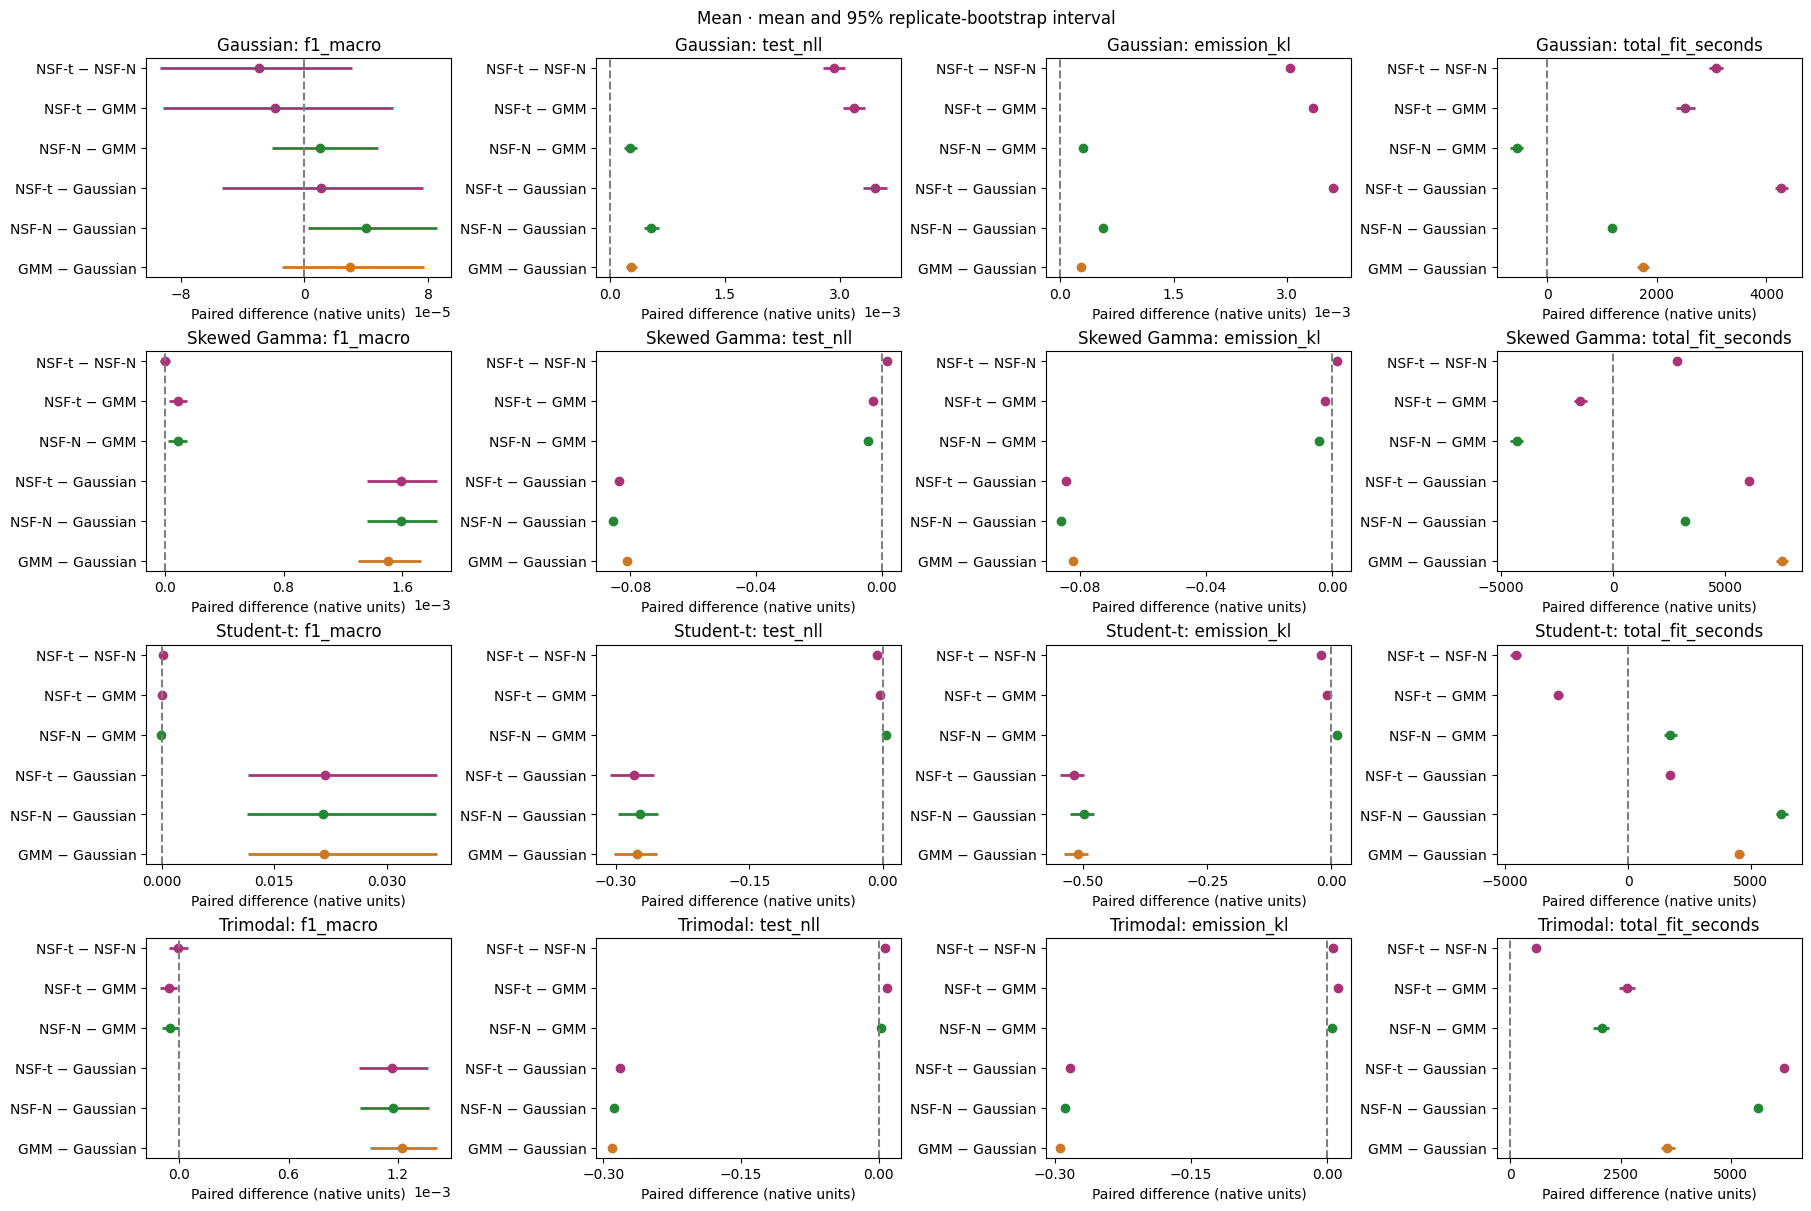

In [14]:
show_and_save(experiment.plot_differences(paired_differences, "mean",
                                         difference_metrics),
              "mean_paired_model_differences")

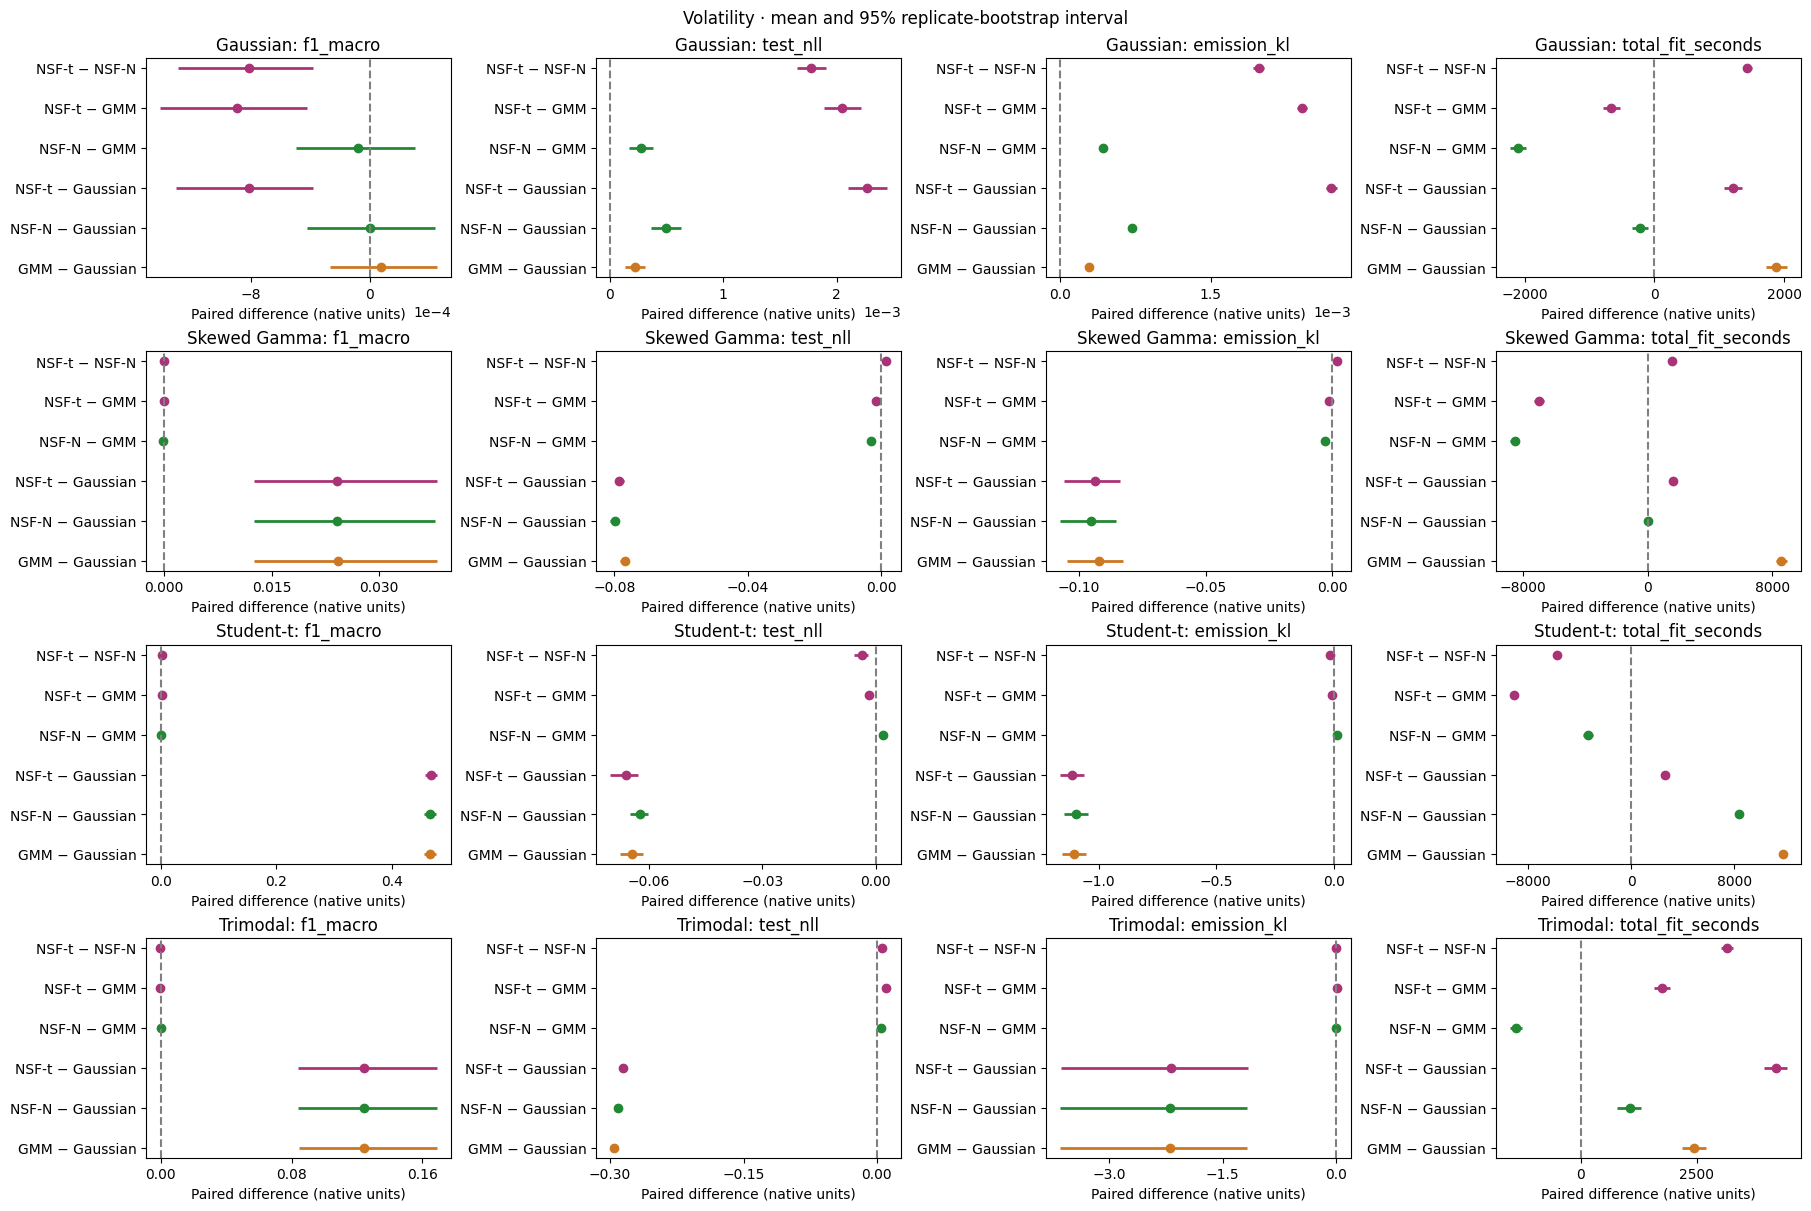

In [15]:
show_and_save(experiment.plot_differences(paired_differences, "volatility",
                                         difference_metrics),
              "volatility_paired_model_differences")

### Confusion matrices and per-state classification

Pool the same complete four-model replicate groups. Rows are true states;
columns are aligned predicted states. Each tile shows its count and row
percentage, with a common 0–100% color scale. Per-state panels show mean ± SD.

In [16]:
state_keys = experiment.KEYS + ["model", "condition"]
state_summary = run["per_state"].merge(
    clean[state_keys], on=state_keys, validate="many_to_one"
).groupby(group_columns + ["state"])[["precision", "recall", "f1", "support"]].agg(
    ["mean", "std"]
)
save_table(state_summary, "per_state_summary")

precision            \
                                                             mean       std   
regime     family   n_train model                 state                       
mean       Gaussian 20000   GMM HMM               0      0.997287  0.002646   
                                                  1      0.996758  0.002462   
                                                  2      0.998013  0.002362   
                            Gaussian HMM          0      0.997365  0.002624   
                                                  1      0.996631  0.002450   
...                                                           ...       ...   
volatility Trimodal 20000   RQ-NSF Gaussian base  1      0.994570  0.004121   
                                                  2      0.997371  0.002829   
                            RQ-NSF Student-t base 0      0.991099  0.006324   
                                                  1      0.994425  0.004221   
                                                  2      0.997359  0.002887   

                                                           recall            \
                                                             mean       std   
regime     family   n_train model                 state                       
mean       Gaussian 20000   GMM HMM               0      0.997813  0.002304   
                                                  1      0.996531  0.002316   
                                                  2      0.997992  0.002007   
                            Gaussian HMM          0      0.997794  0.002329   
                                                  1      0.996554  0.002296   
...                                                           ...       ...   
volatility Trimodal 20000   RQ-NSF Gaussian base  1      0.993571  0.004508   
                                                  2      0.993389  0.004492   
                            RQ-NSF Student-t base 0      0.997168  0.003132   
                                                  1      0.993286  0.004545   
                                                  2      0.993023  0.005019   

                                                               f1            \
                                                             mean       std   
regime     family   n_train model                 state                       
mean       Gaussian 20000   GMM HMM               0      0.997547  0.001820   
                                                  1      0.996642  0.001658   
                                                  2      0.998001  0.001826   
                            Gaussian HMM          0      0.997576  0.001734   
                                                  1      0.996590  0.001683   
...                                                           ...       ...   
volatility Trimodal 20000   RQ-NSF Gaussian base  1      0.994064  0.003538   
                                                  2      0.995369  0.002707   
                            RQ-NSF Student-t base 0      0.994117  0.004142   
                                                  1      0.993848  0.003450   
                                                  2      0.995179  0.003162   

                                                         support              
                                                            mean         std  
regime     family   n_train model                 state                       
mean       Gaussian 20000   GMM HMM               0      1652.60  495.678415  
                                                  1      1772.41  526.828707  
                                                  2      1574.99  517.991820  
                            Gaussian HMM          0      1652.60  495.678415  
                                                  1      1772.41  526.828707  
...                                                          ...         ...  
volatility Trimodal 2000

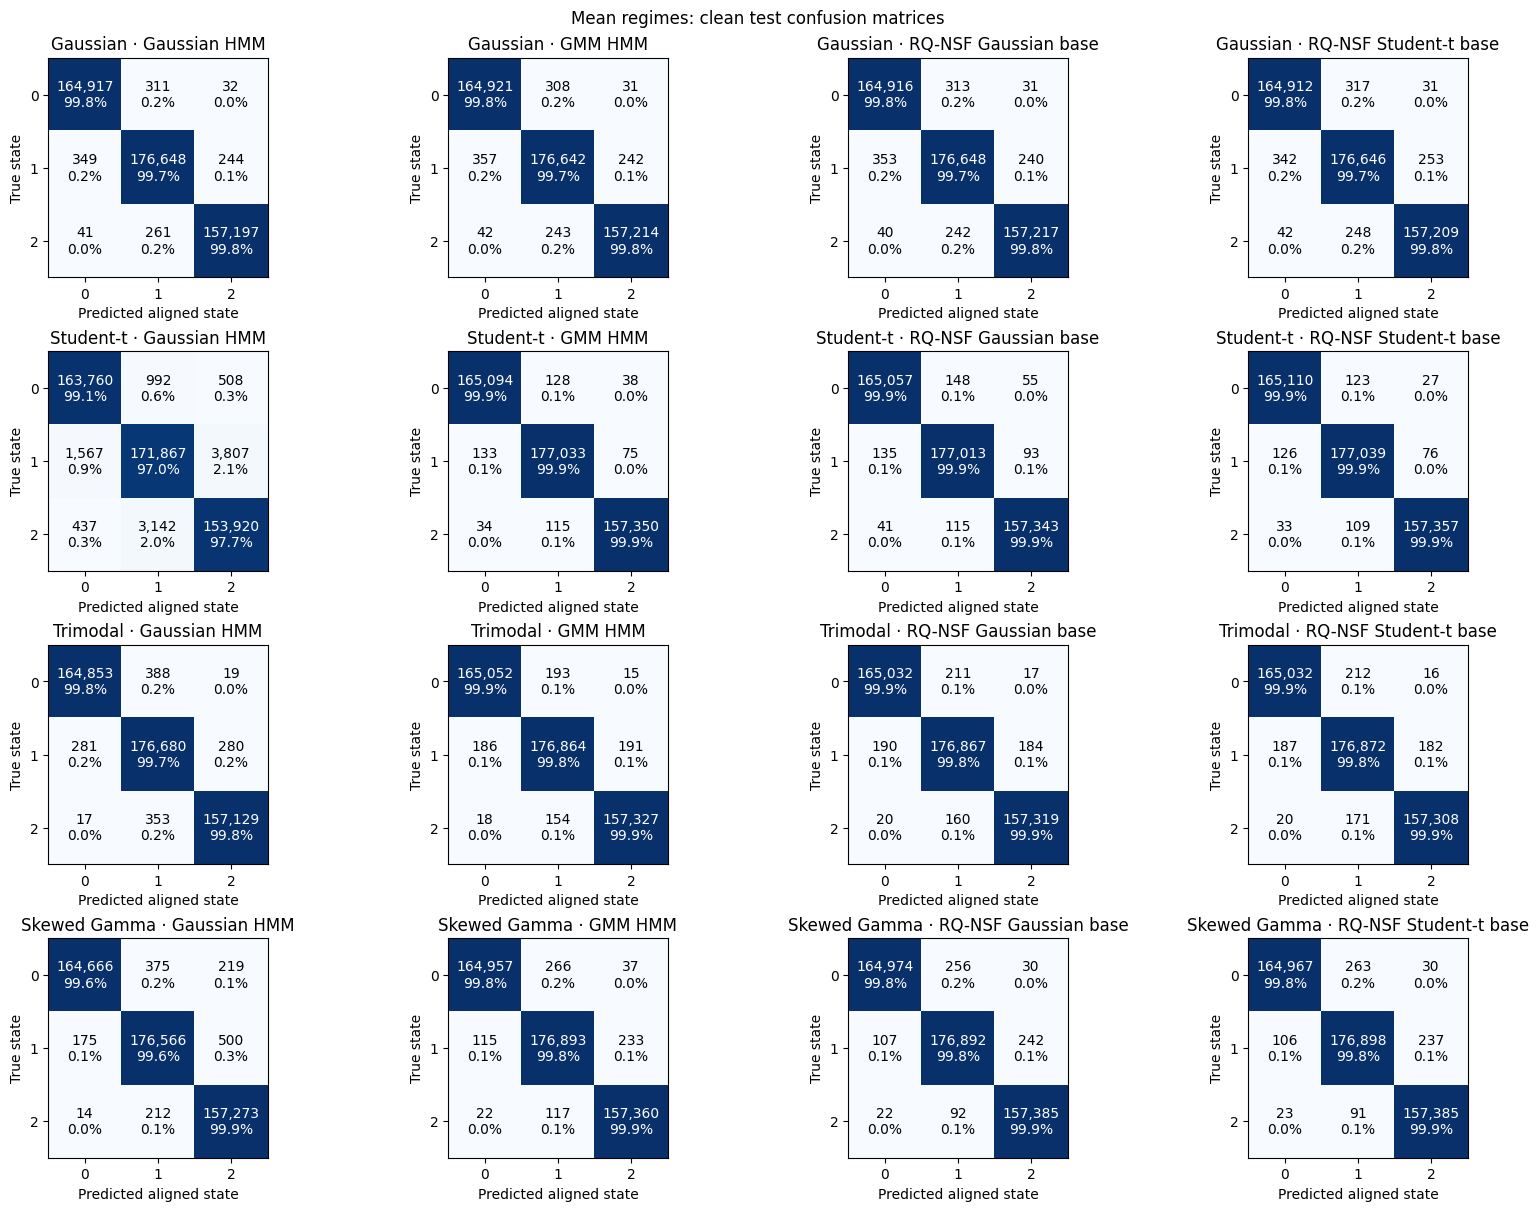

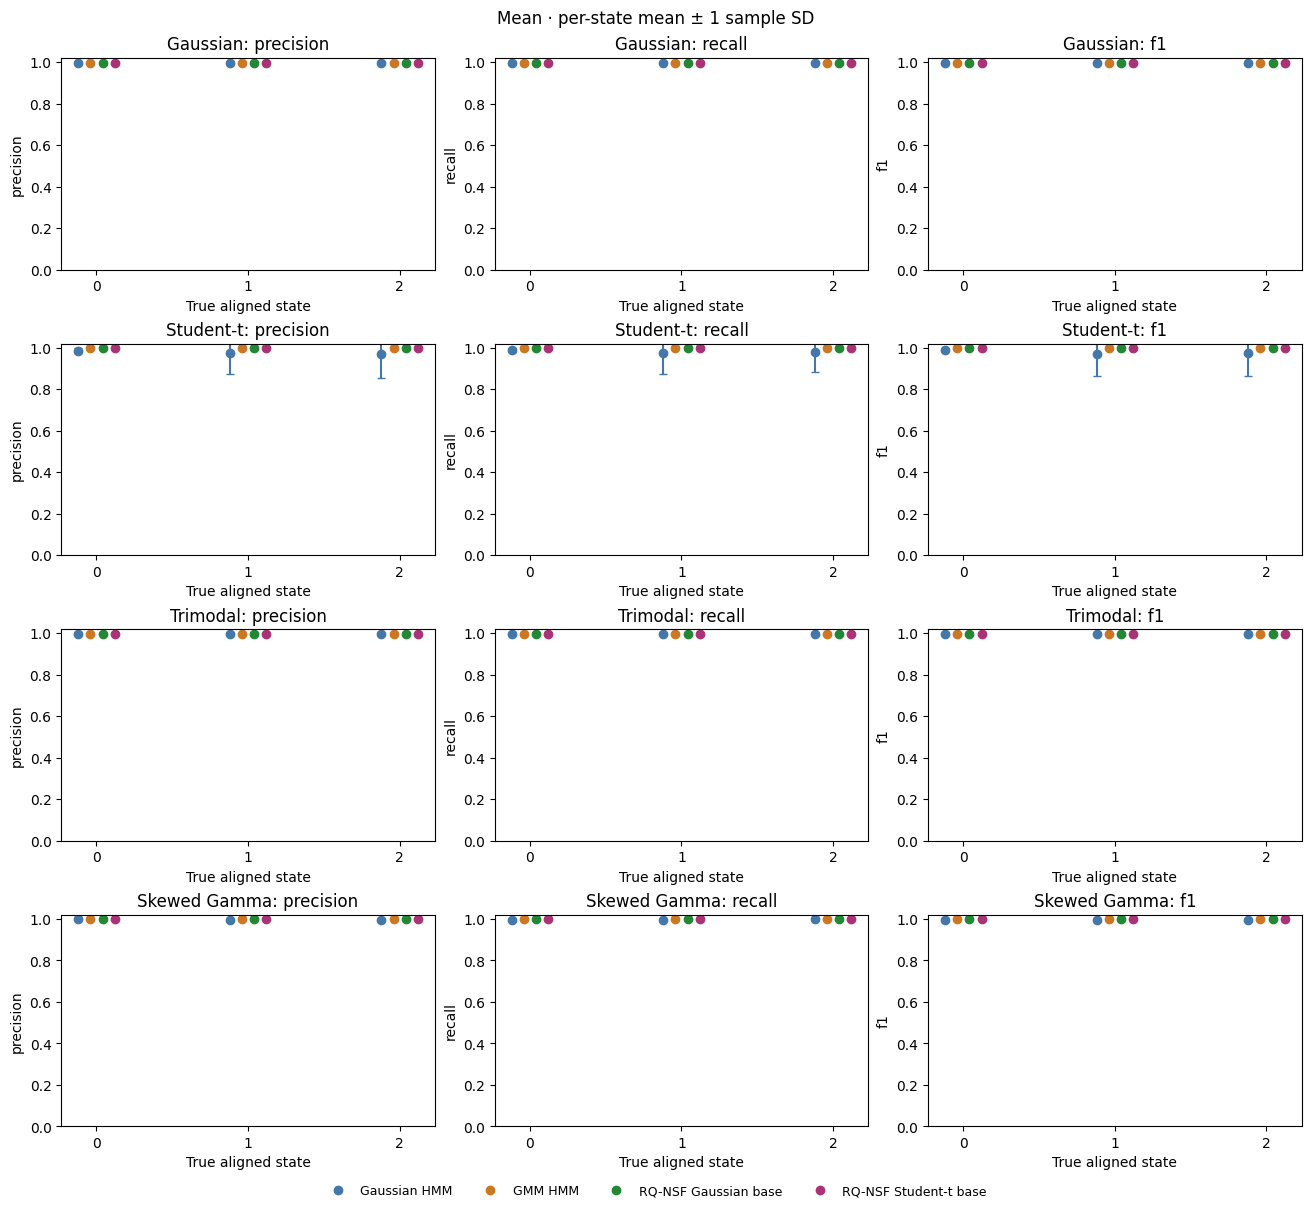

In [17]:
show_and_save(experiment.plot_confusions(run["confusion"], clean, "mean"),
              "mean_confusion_matrices")
show_and_save(experiment.plot_per_state(run["per_state"], clean, "mean"),
              "mean_per_state_classification")

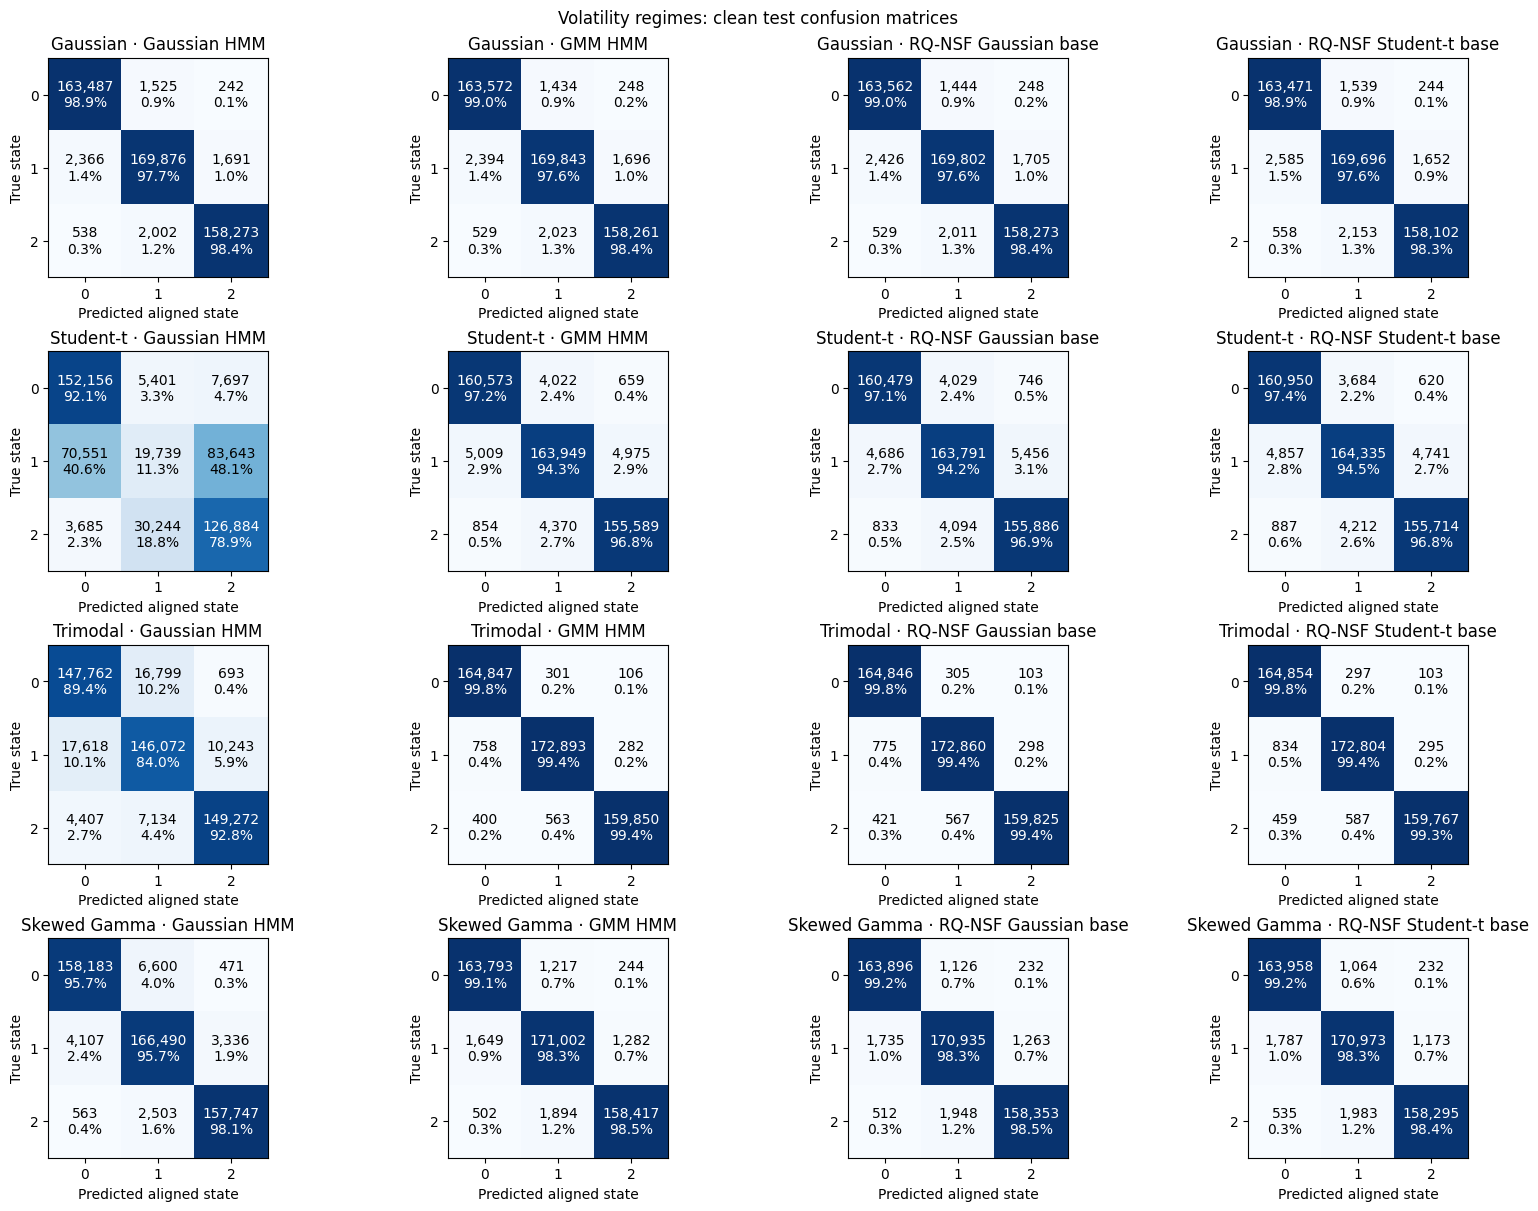

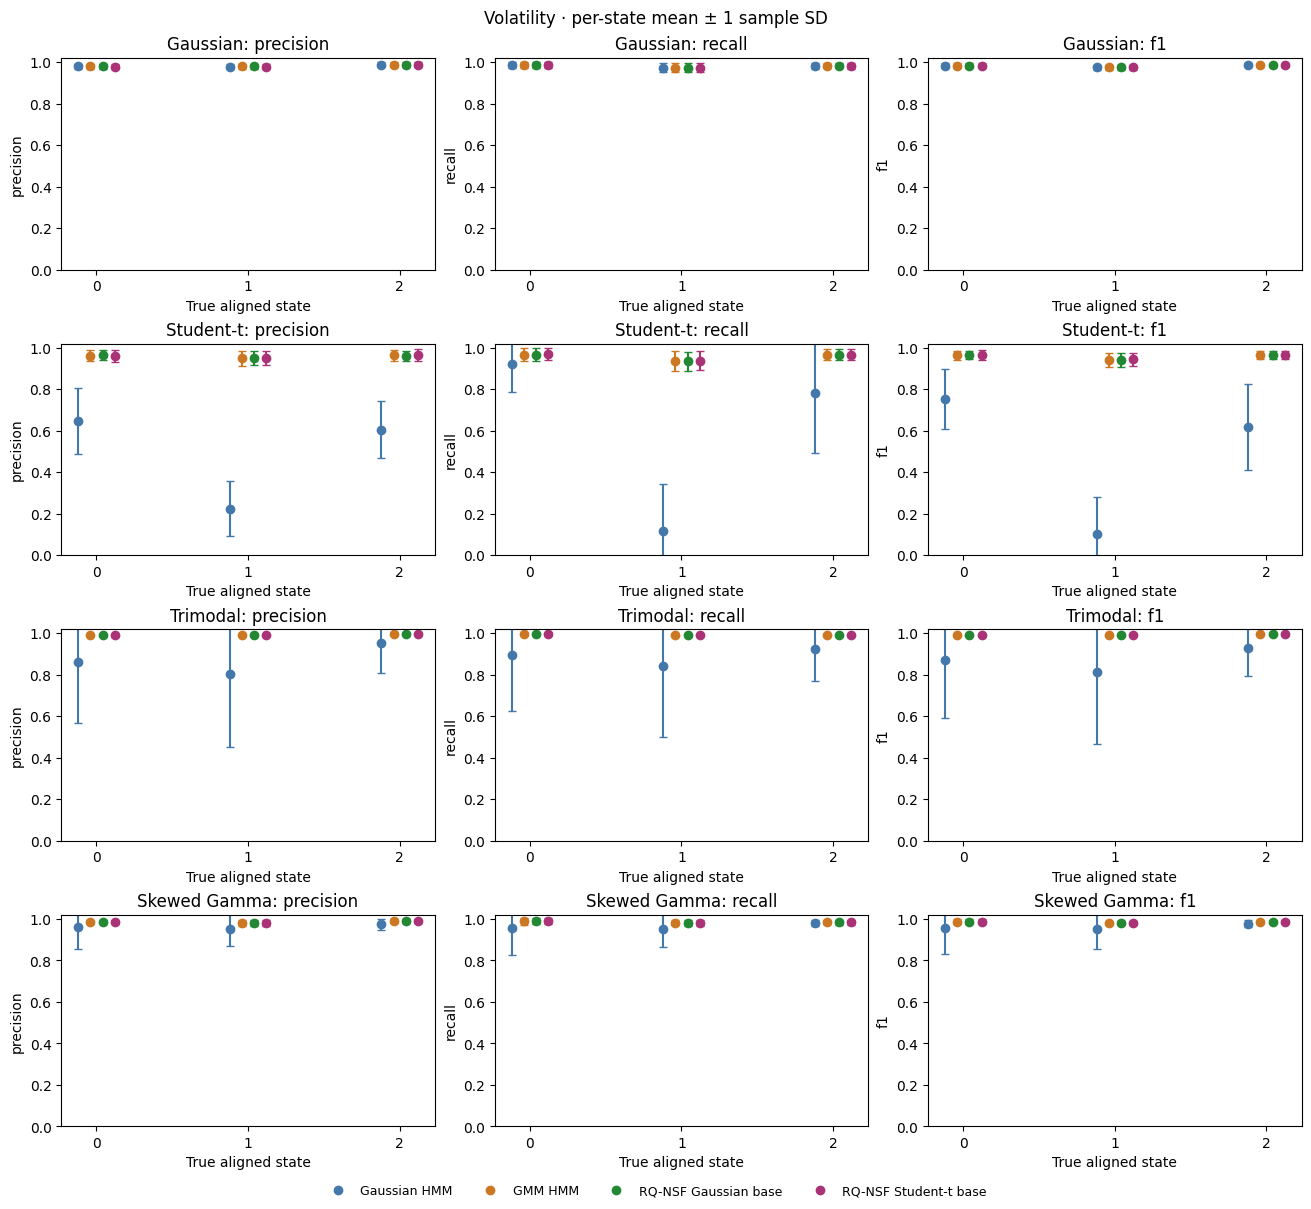

In [18]:
show_and_save(experiment.plot_confusions(run["confusion"], clean, "volatility"),
              "volatility_confusion_matrices")
show_and_save(experiment.plot_per_state(run["per_state"], clean, "volatility"),
              "volatility_per_state_classification")

### True and fitted emission densities

Use the fixed `EMISSION_DENSITY_REPLICATE` (default 0), independently of test
performance. Each panel uses the original window of ±5 true SD around a state
mean. These curves evaluate saved densities on a plotting grid; models are
restored without fitting and use their saved training-derived state alignment.

#### Mean regime: all four fitted emissions

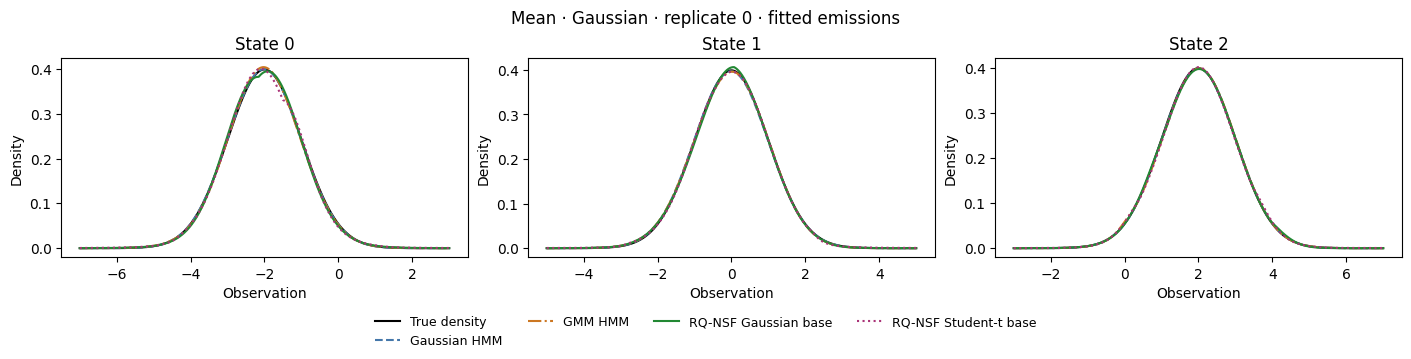

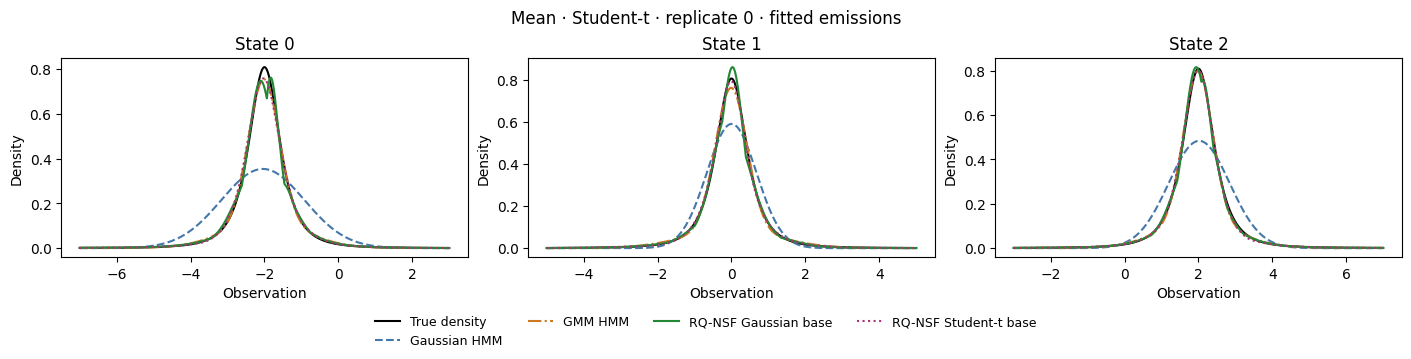

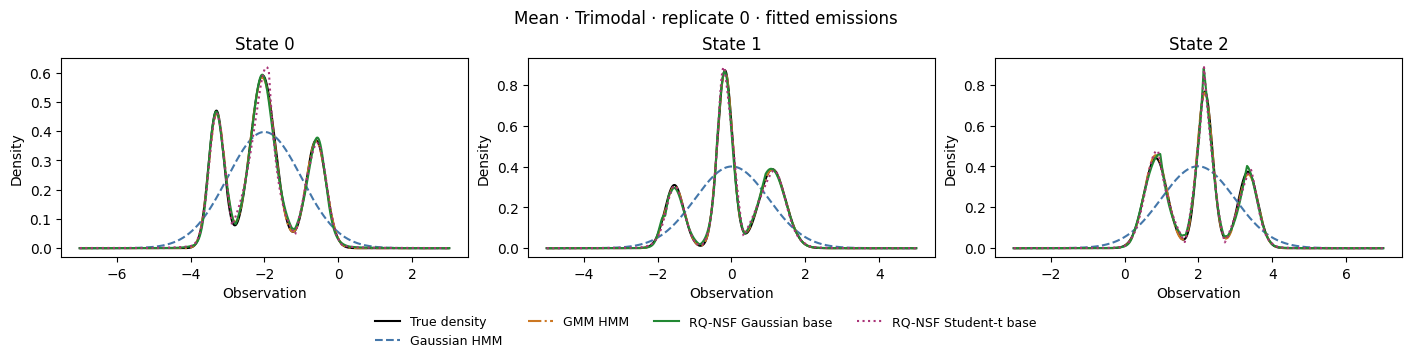

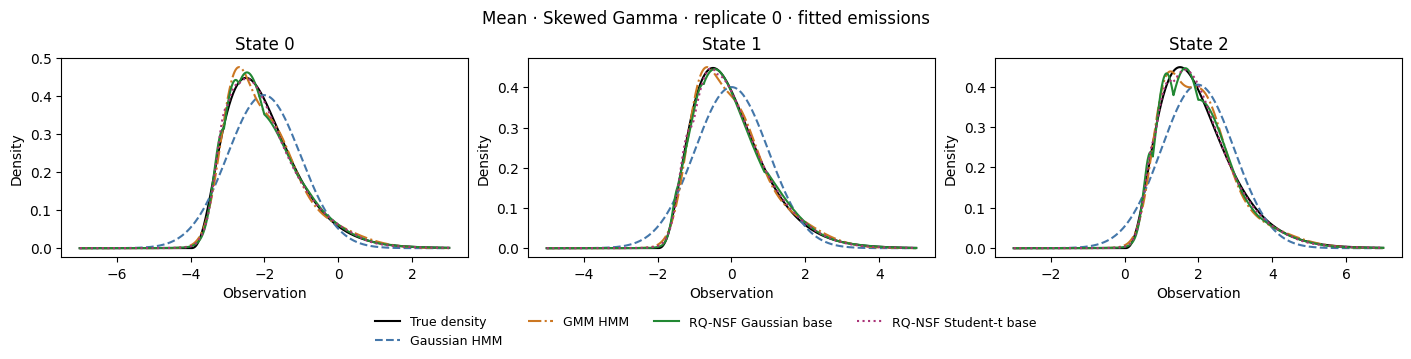

In [19]:
with saved.emission_plot_adapter():
    for family in EXAMPLE_FAMILIES:
        show_and_save(experiment.plot_emissions(
            sources["mean"], COMPARISON_DIRECTORY, family,
            replicate=EMISSION_DENSITY_REPLICATE
        ), f"mean_{family}_replicate_{EMISSION_DENSITY_REPLICATE}_fitted_emissions")

#### Volatility regime: all four fitted emissions

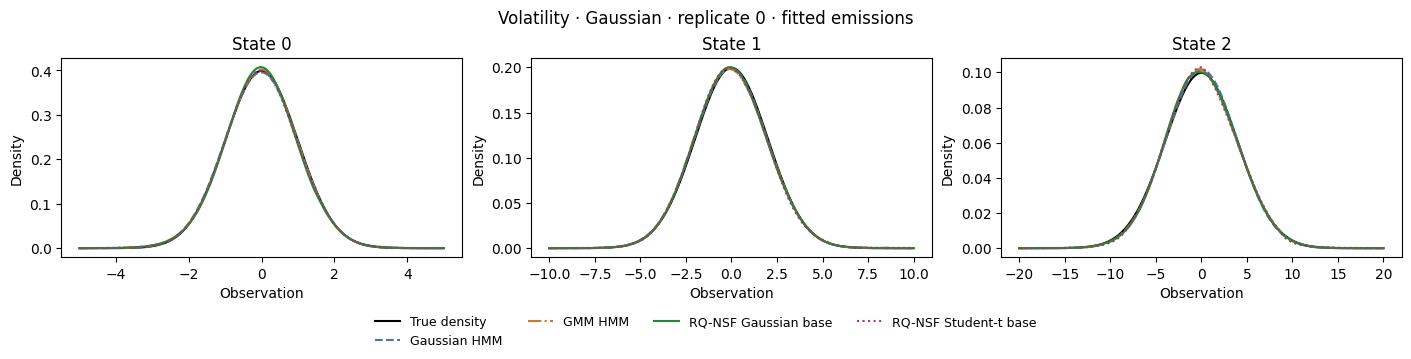

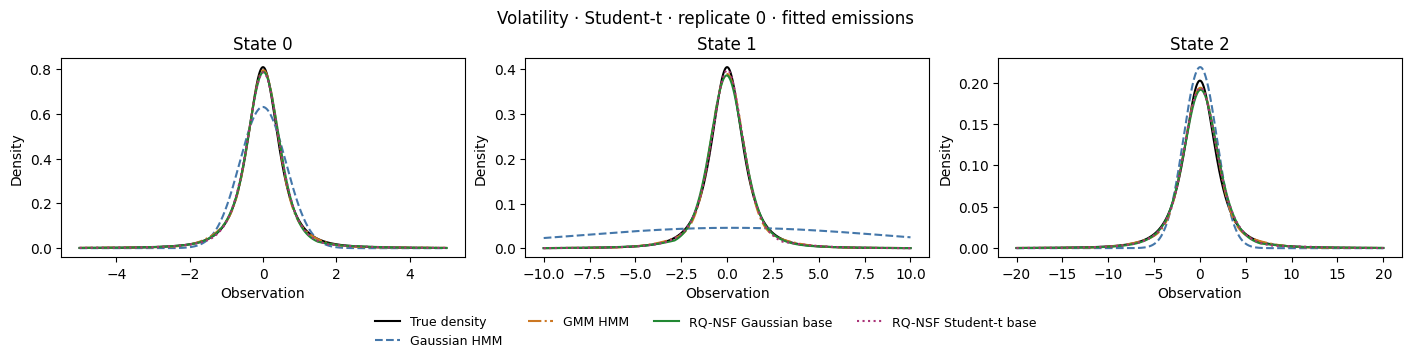

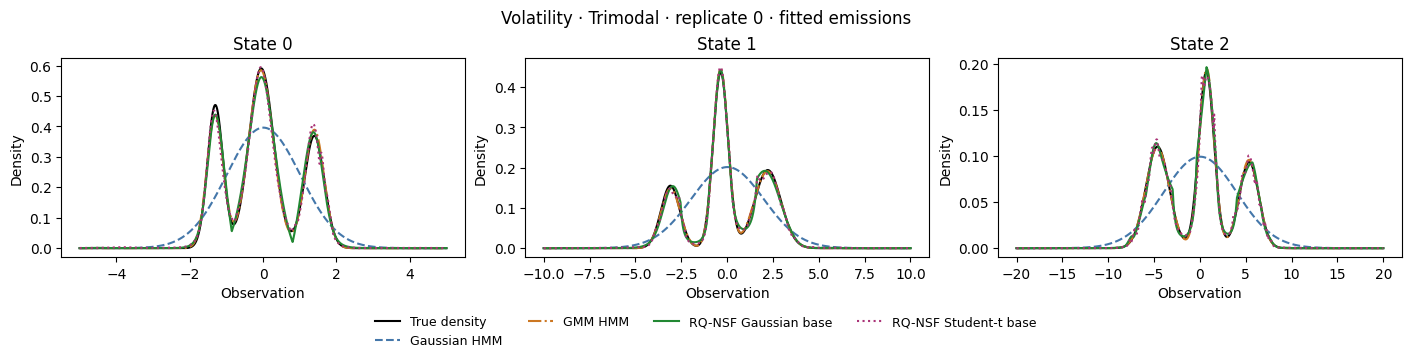

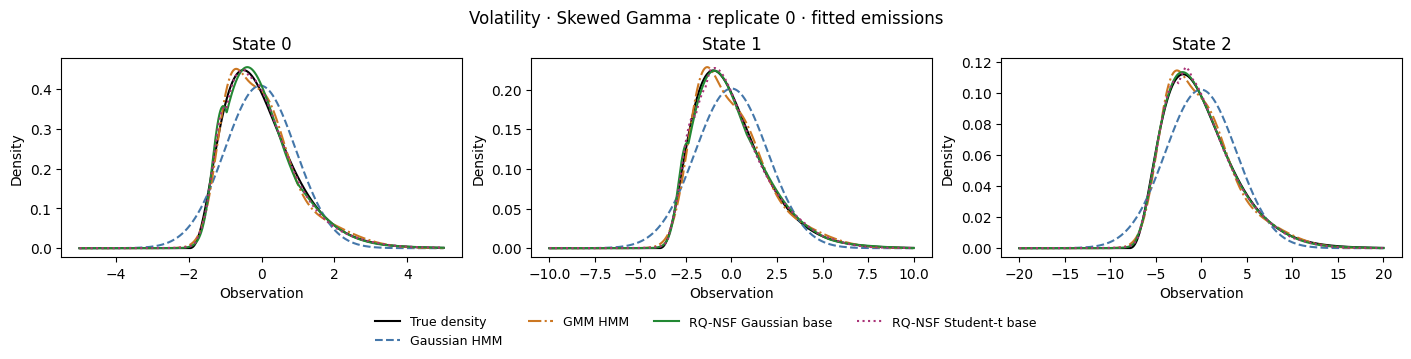

In [20]:
with saved.emission_plot_adapter():
    for family in EXAMPLE_FAMILIES:
        show_and_save(experiment.plot_emissions(
            sources["volatility"], COMPARISON_DIRECTORY, family,
            replicate=EMISSION_DENSITY_REPLICATE
        ), f"volatility_{family}_replicate_{EMISSION_DENSITY_REPLICATE}_fitted_emissions")

### True and fitted flow emission densities

The same fixed replicate, focusing on the two flow bases against truth.

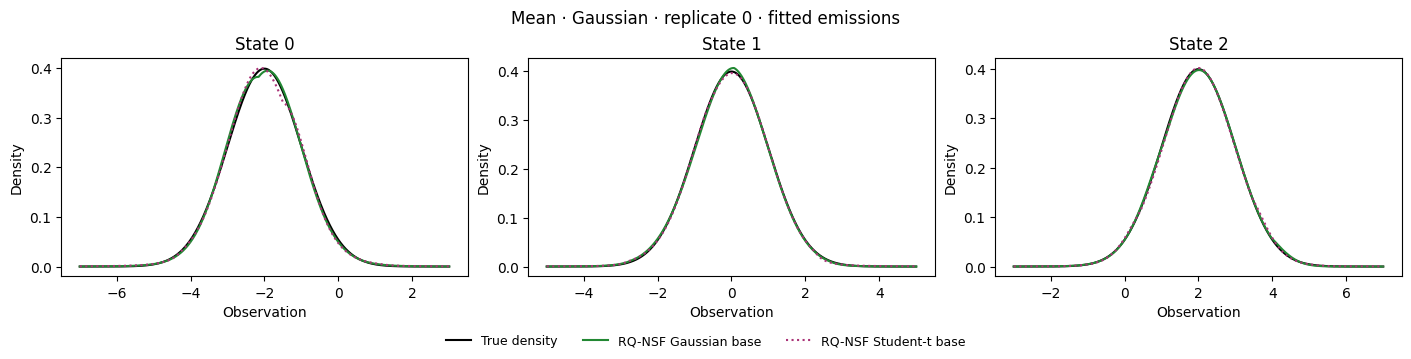

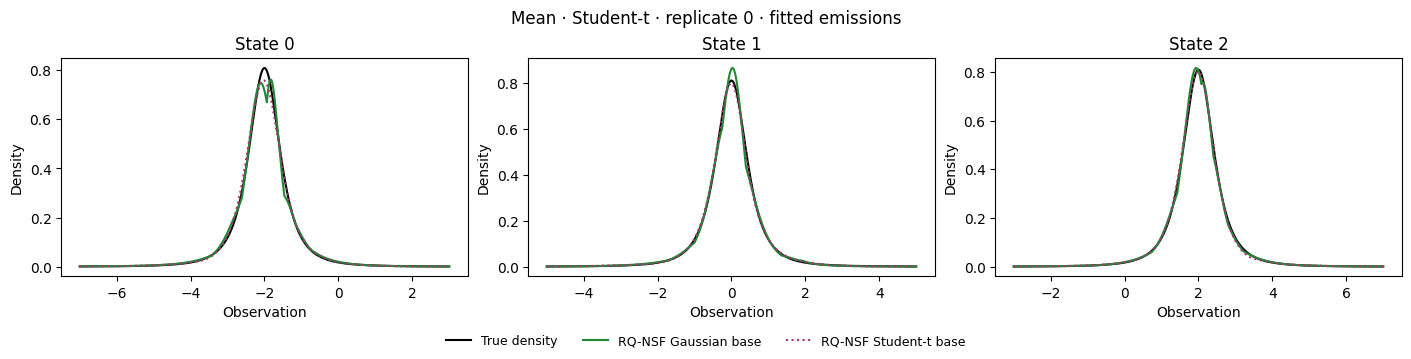

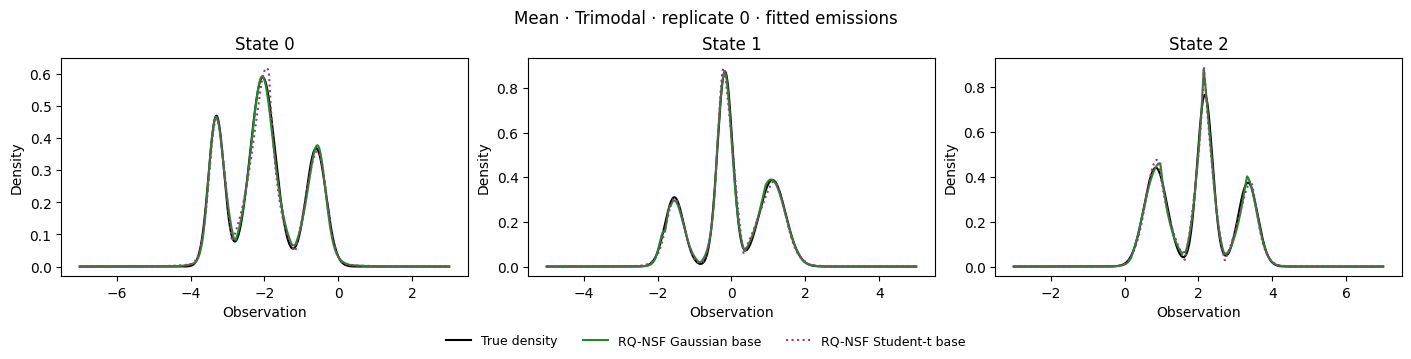

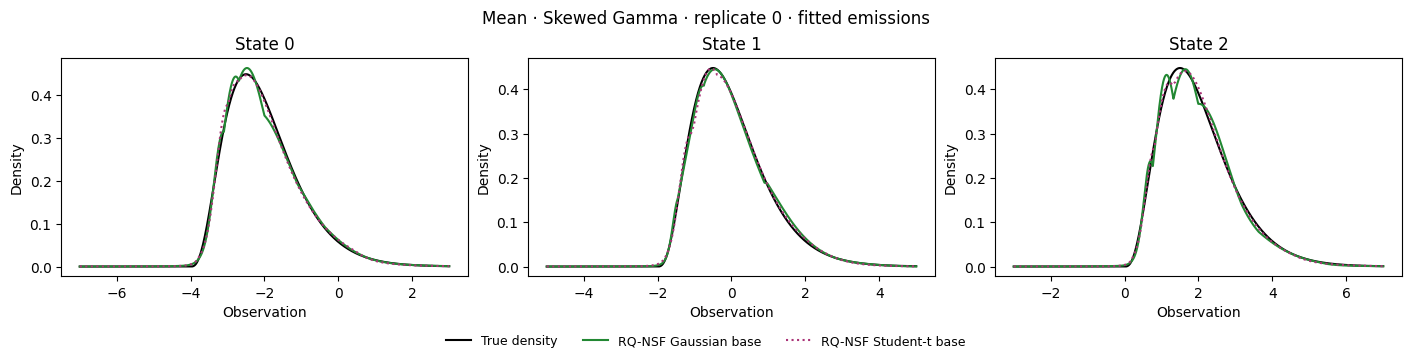

In [21]:
with saved.emission_plot_adapter():
    for family in EXAMPLE_FAMILIES:
        show_and_save(experiment.plot_emissions(
            sources["mean"], COMPARISON_DIRECTORY, family, flow_only=True,
            replicate=EMISSION_DENSITY_REPLICATE
        ), f"mean_{family}_replicate_{EMISSION_DENSITY_REPLICATE}_flow_emissions")

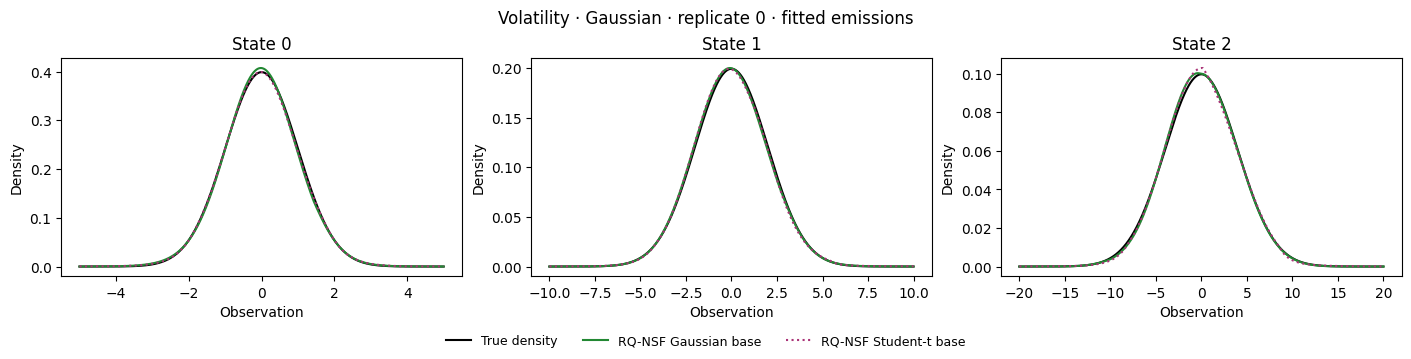

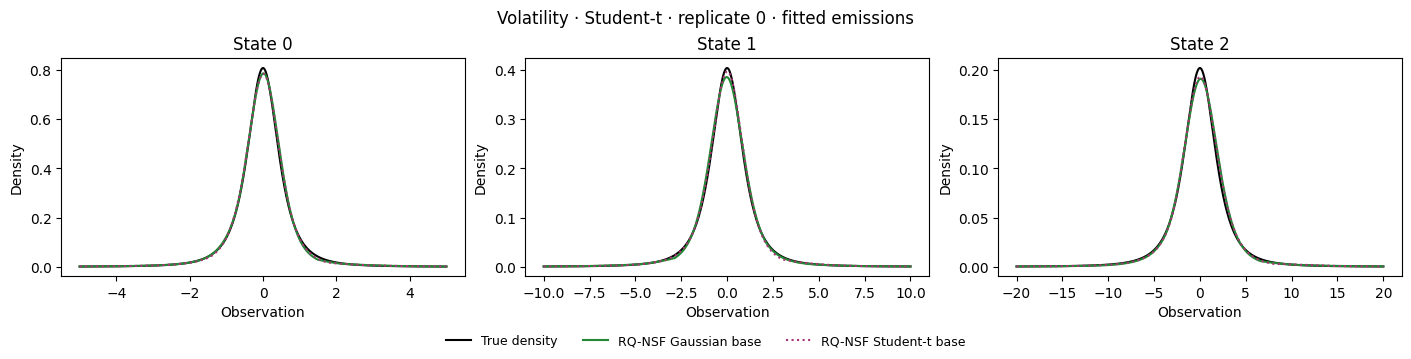

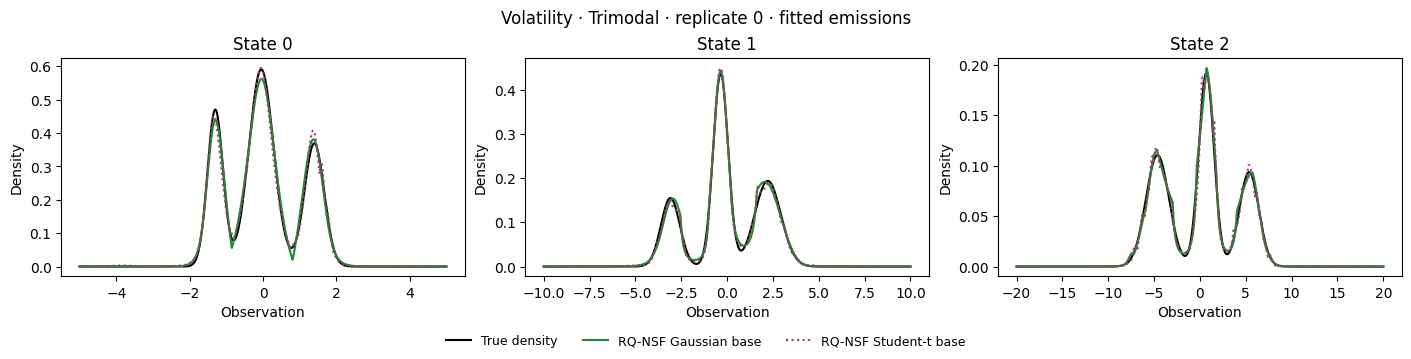

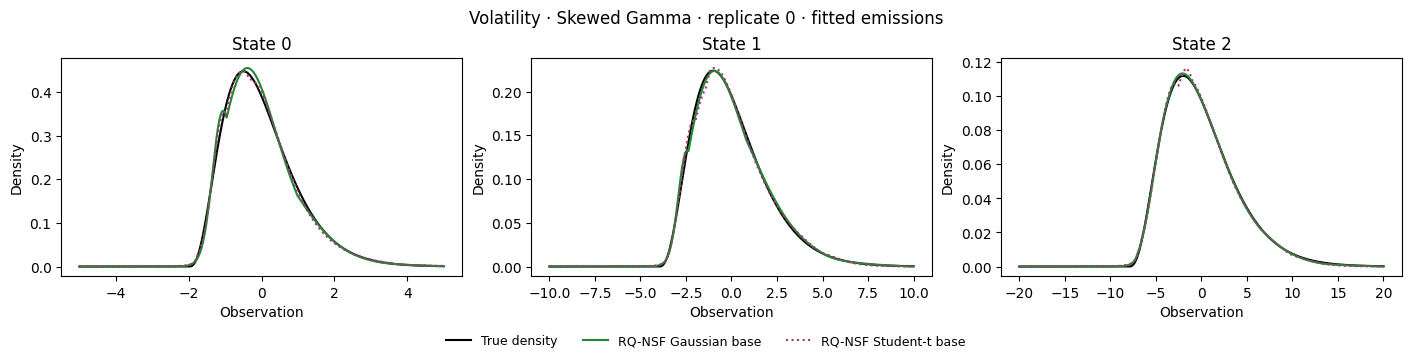

In [22]:
with saved.emission_plot_adapter():
    for family in EXAMPLE_FAMILIES:
        show_and_save(experiment.plot_emissions(
            sources["volatility"], COMPARISON_DIRECTORY, family, flow_only=True,
            replicate=EMISSION_DENSITY_REPLICATE
        ), f"volatility_{family}_replicate_{EMISSION_DENSITY_REPLICATE}_flow_emissions")

### Decoded state paths

Use `DECODED_PATH_FAMILY`, `DECODED_PATH_REPLICATE`, and `DECODED_POINTS` from
setup. Read the saved clean and noisy predictions on identical observations;
crosses mark incorrect states. No decoding is recomputed here.

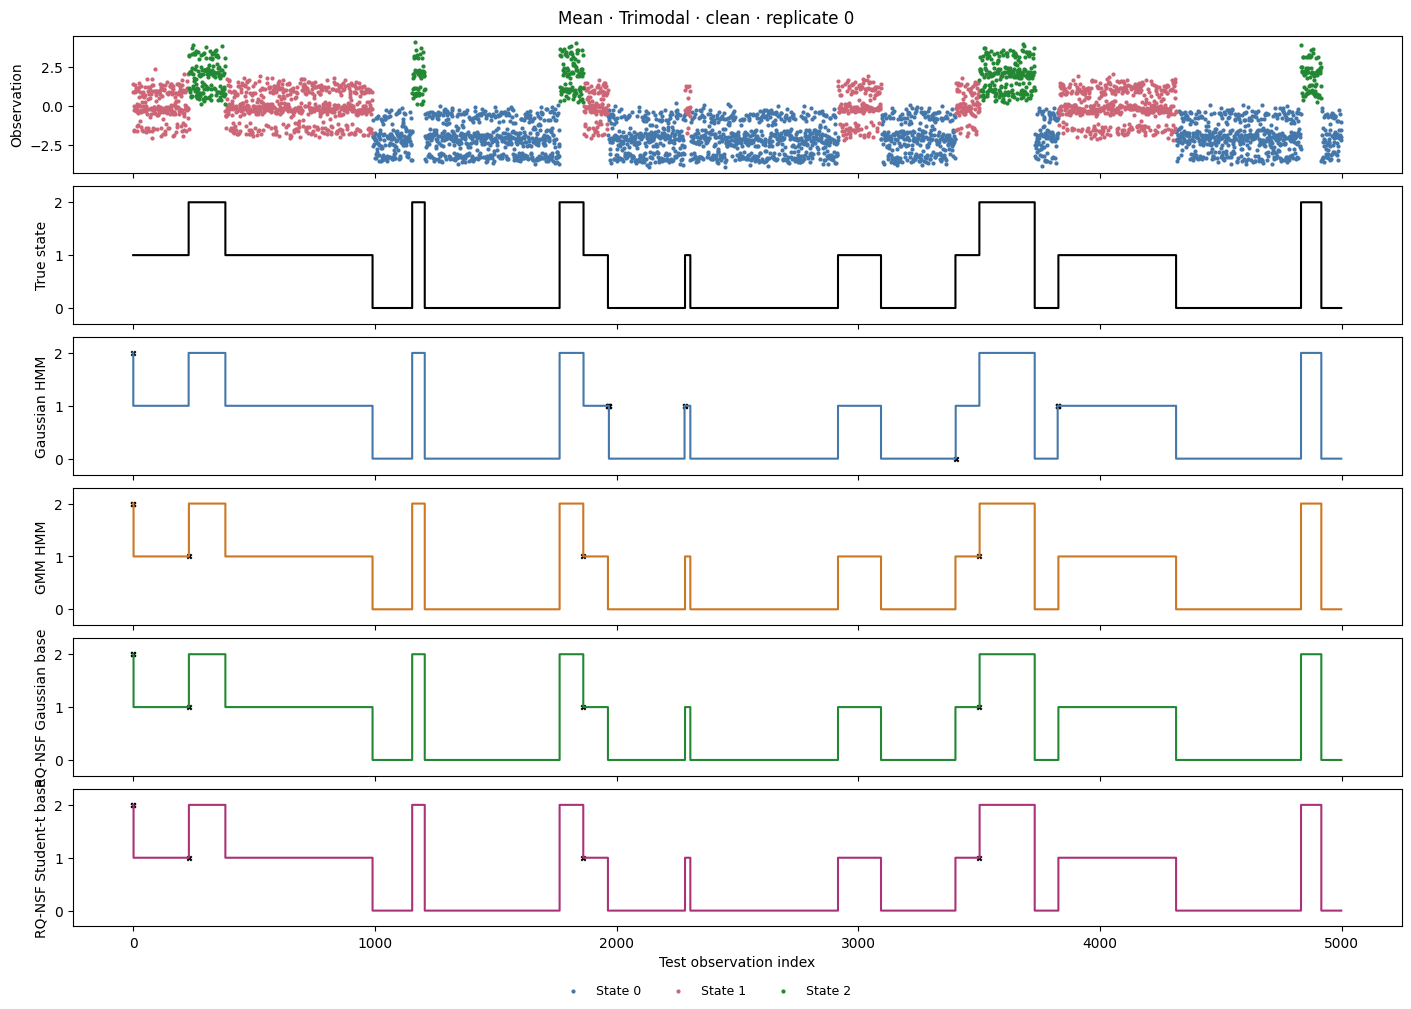

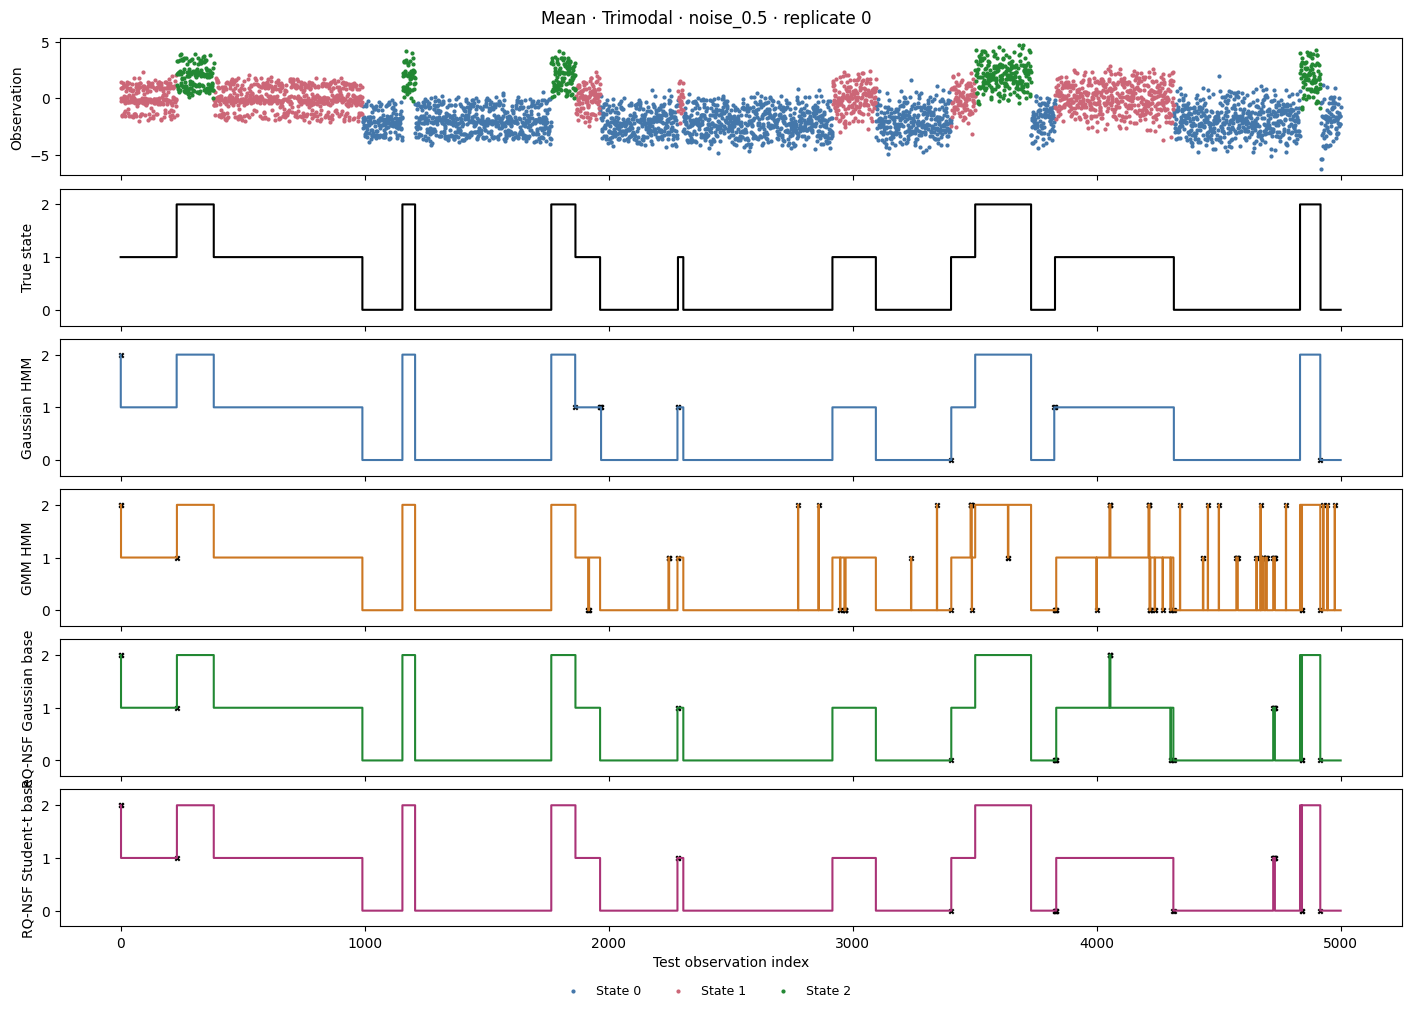

In [23]:
for condition in DECODED_CONDITIONS:
    show_and_save(saved.plot_decoding(
        sources["mean"], DECODED_PATH_FAMILY, condition,
        DECODED_PATH_REPLICATE, DECODED_POINTS
    ), f"mean_{DECODED_PATH_FAMILY}_{condition}_replicate_{DECODED_PATH_REPLICATE}_decoded_paths")

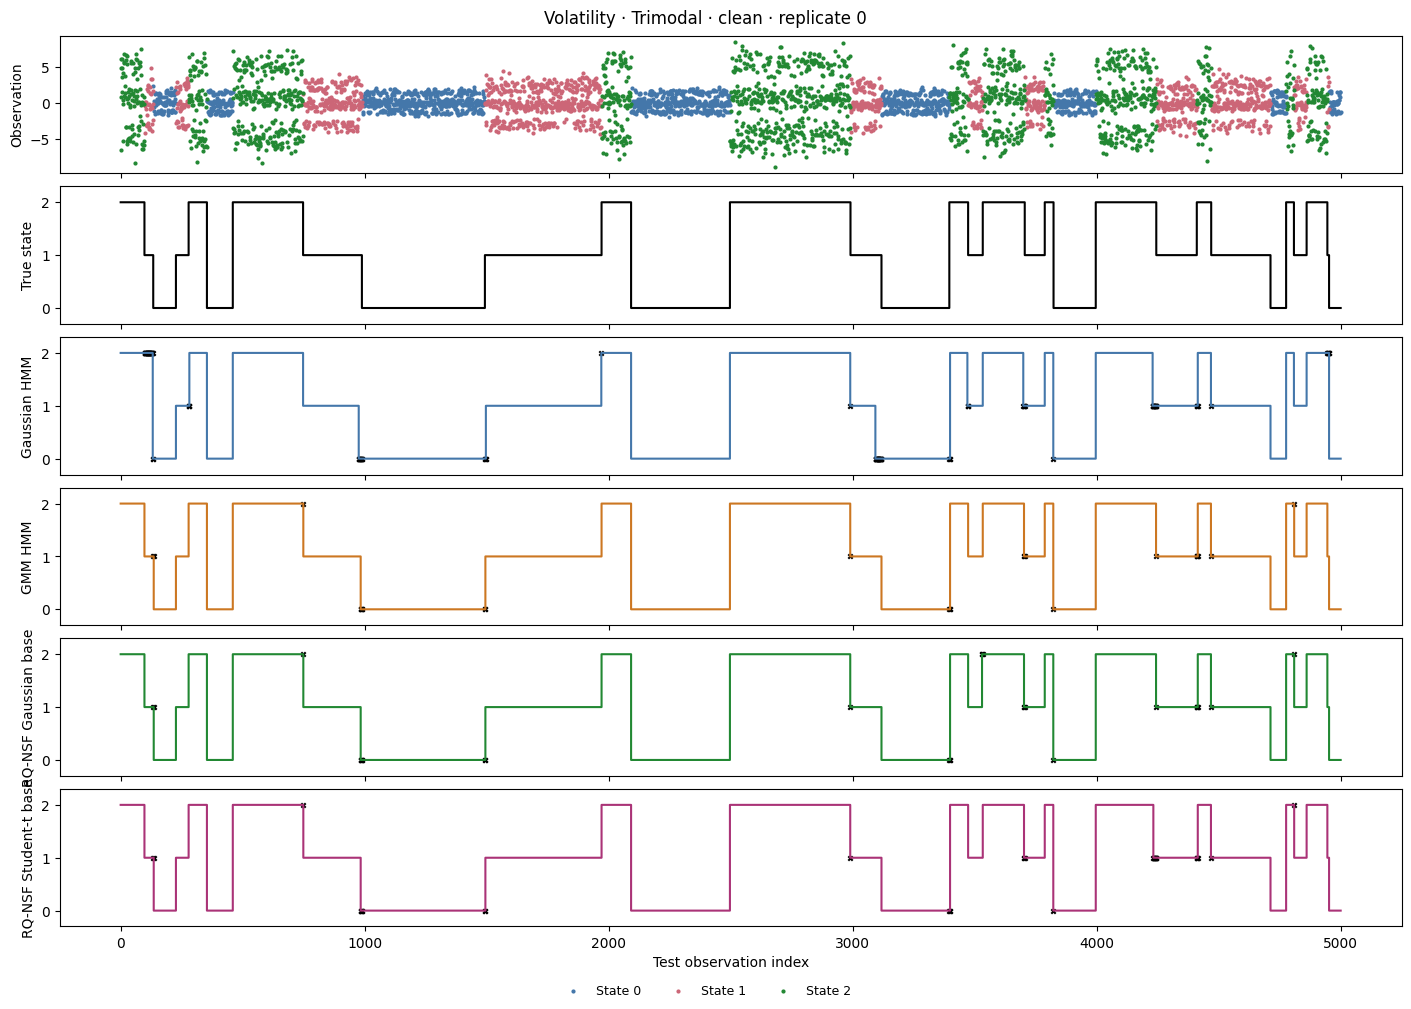

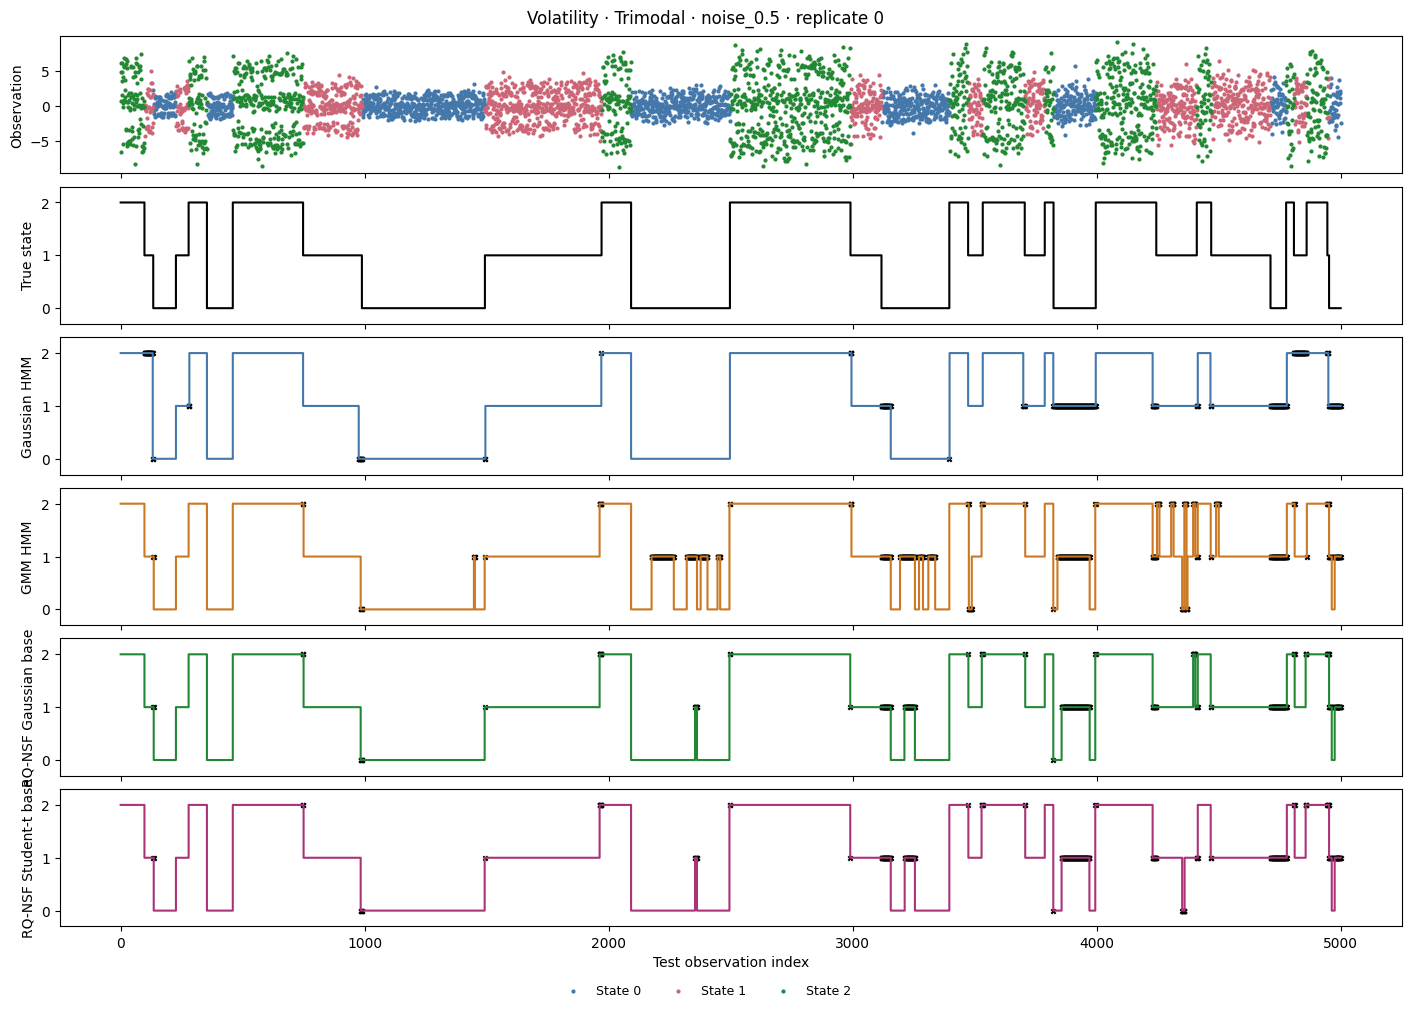

In [24]:
for condition in DECODED_CONDITIONS:
    show_and_save(saved.plot_decoding(
        sources["volatility"], DECODED_PATH_FAMILY, condition,
        DECODED_PATH_REPLICATE, DECODED_POINTS
    ), f"volatility_{DECODED_PATH_FAMILY}_{condition}_replicate_{DECODED_PATH_REPLICATE}_decoded_paths")

### Noise robustness

Compare all models on matched clean and noisy versions of each test sequence.
Noise grows over the sequence as in the original experiments. Error bars are
replicate mean ± sample SD. A paired table also records noisy-minus-clean
changes within each model and dataset replicate.

In [25]:
noise_metrics = ["f1_macro", "state_brier_score", "test_nll", "absolute_switch_count_error"]
noise_summary = robust.groupby(group_columns + ["condition"])[noise_metrics].agg(
    ["mean", "std", "count"]
)
save_table(noise_summary, "noise_robustness_summary")
clean_scores = robust[robust.condition == "clean"]
noise_changes = robust.merge(
    clean_scores[experiment.KEYS + ["model"] + noise_metrics],
    on=experiment.KEYS + ["model"], suffixes=("", "_clean"), validate="many_to_one"
)
for metric in noise_metrics:
    noise_changes[f"{metric}_noisy_minus_clean"] = noise_changes[metric] - noise_changes[f"{metric}_clean"]
save_table(noise_changes, "noisy_minus_clean", index=False)
display(noise_changes.groupby(["regime", "model", "condition"])[
    [f"{metric}_noisy_minus_clean" for metric in noise_metrics]
].mean().round(5))

f1_macro_noisy_minus_clean  \
regime     model                 condition                                
mean       GMM HMM               clean                          0.00000   
                                 noise_0.1                     -0.00008   
                                 noise_0.25                    -0.00085   
                                 noise_0.5                     -0.00912   
           Gaussian HMM          clean                          0.00000   
                                 noise_0.1                     -0.00004   
                                 noise_0.25                    -0.00056   
                                 noise_0.5                     -0.00473   
           RQ-NSF Gaussian base  clean                          0.00000   
                                 noise_0.1                     -0.00010   
                                 noise_0.25                    -0.00057   
                                 noise_0.5                     -0.00547   
           RQ-NSF Student-t base clean                          0.00000   
                                 noise_0.1                     -0.00010   
                                 noise_0.25                    -0.00056   
                                 noise_0.5                     -0.00466   
volatility GMM HMM               clean                          0.00000   
                                 noise_0.1                     -0.00108   
                                 noise_0.25                    -0.03297   
                                 noise_0.5                     -0.17702   
           Gaussian HMM          clean                          0.00000   
                                 noise_0.1                     -0.00027   
                                 noise_0.25                    -0.00477   
                                 noise_0.5                     -0.08752   
           RQ-NSF Gaussian base  clean                          0.00000   
                                 noise_0.1                     -0.00109   
                                 noise_0.25                    -0.02955   
                                 noise_0.5                     -0.16736   
           RQ-NSF Student-t base clean                          0.00000   
                                 noise_0.1                     -0.00104   
                                 noise_0.25                    -0.02778   
                                 noise_0.5                     -0.15986   

                                             state_brier_score_noisy_minus_clean  \
regime     model                 condition                                         
mean       GMM HMM               clean                                   0.00000   
                                 noise_0.1                               0.00009   
                                 noise_0.25                              0.00132   
                                 noise_0.5                               0.01430   
           Gaussian HMM          clean                                   0.00000   
                                 noise_0.1                               0.00010   
                                 noise_0.25                              0.00092   
                                 noise_0.5                               0.00747   
           RQ-NSF Gaussian base  clean                                   0.00000   
                                 noise_0.1                               0.00010   
                                 noise_0.25                              0.00087   
                                 noise_0.5                               0.00874   
           RQ-NSF Student-t base clean                                   0.00000   
                                 noise_0.1                               0.00009   
                                 noise_0.25                              0.00082   
                                 noise_0.5                        

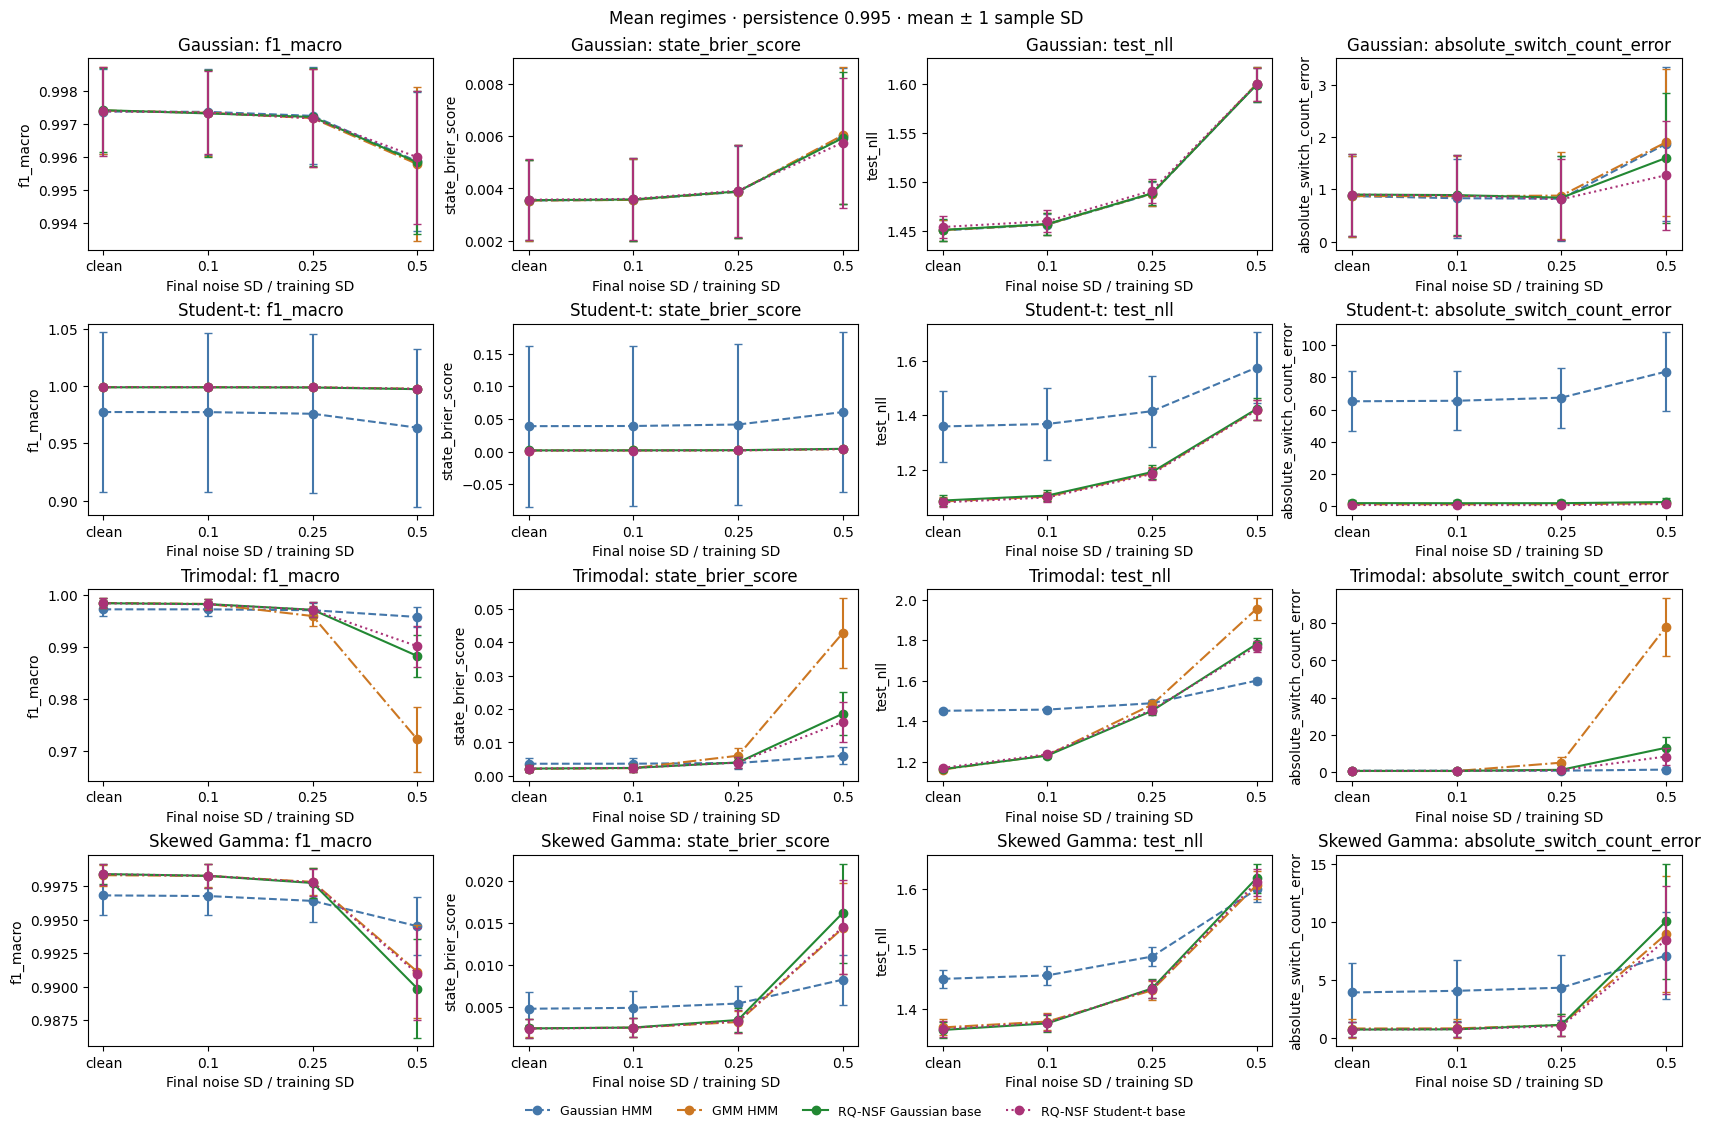

In [26]:
metric_plot(robust, "mean", noise_metrics,
            "mean_noise_robustness", noise=True)

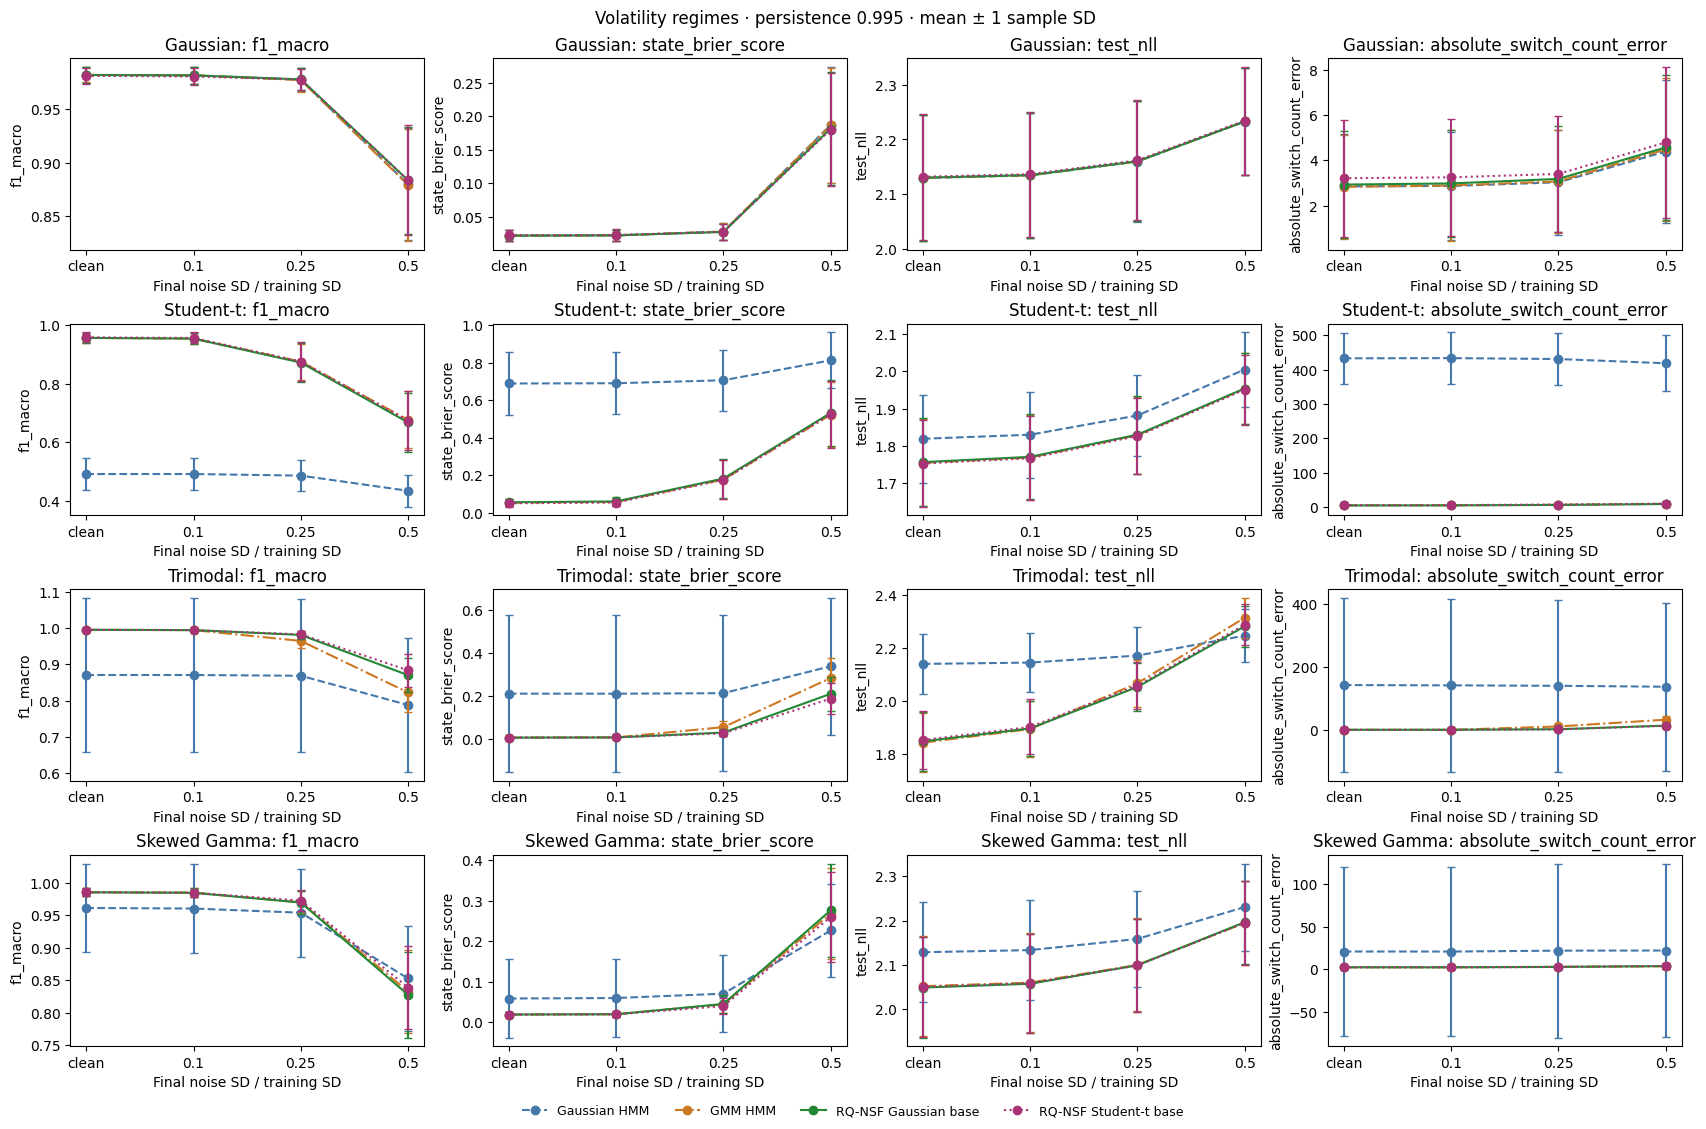

In [27]:
metric_plot(robust, "volatility", noise_metrics,
            "volatility_noise_robustness", noise=True)

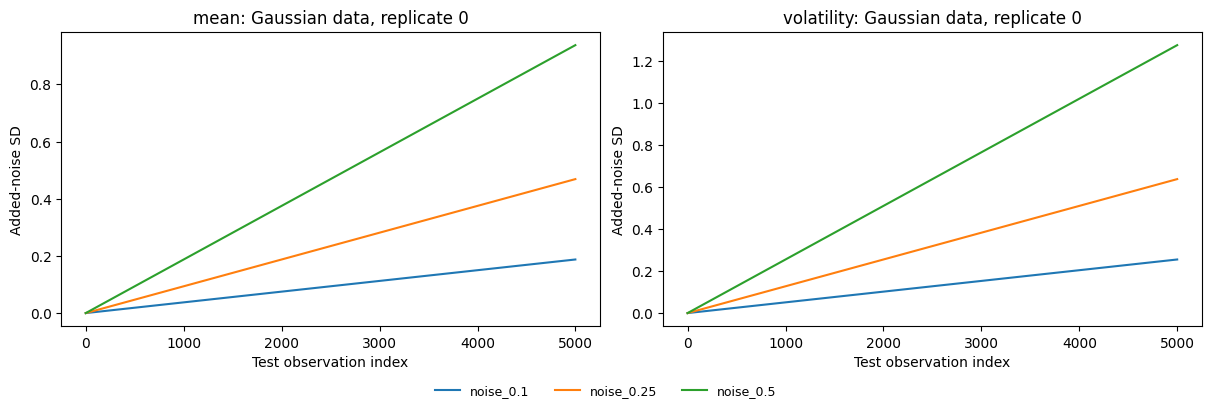

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for axis, regime in zip(axes, REGIMES):
    source = sources[regime]
    data = source.data(0, "Gaussian")
    size = max(source.settings["train_sizes"])
    variants = source.variants(data["train"].iloc[:size], data["test"], 0, "Gaussian", size)
    for condition, frame in variants.items():
        if condition != "clean":
            axis.plot(frame.time, frame.noise_std, label=condition)
    axis.set(title=f"{regime}: Gaussian data, replicate 0",
             xlabel="Test observation index", ylabel="Added-noise SD")
    axis.legend()
show_and_save(fig, "measurement_noise_schedules")

### Fit reliability and computation

Inspect every fitting attempt, not only selected winners. The summed fit
duration counts individual fits that ran concurrently; it is not the elapsed
time you waited for the cluster. History panels show the chosen starts for
Trimodal data at `HISTORY_REPLICATE`.

starts  failures  \
regime     family       n_train model                                     
mean       Gaussian     20000   GMM HMM                 10000         0   
                                Gaussian HMM            10000         0   
                                RQ-NSF Gaussian base    10000         0   
                                RQ-NSF Student-t base   10000         0   
           Skewed Gamma 20000   GMM HMM                 10000         0   
                                Gaussian HMM            10000         0   
                                RQ-NSF Gaussian base    10000         0   
                                RQ-NSF Student-t base   10000         0   
           Student-t    20000   GMM HMM                 10000         0   
                                Gaussian HMM            10000         0   
                                RQ-NSF Gaussian base    10000         0   
                                RQ-NSF Student-t base   10000         0   
           Trimodal     20000   GMM HMM                 10000         0   
                                Gaussian HMM            10000         0   
                                RQ-NSF Gaussian base    10000         0   
                                RQ-NSF Student-t base   10000         0   
volatility Gaussian     20000   GMM HMM                 10000         0   
                                Gaussian HMM            10000         0   
                                RQ-NSF Gaussian base    10000         0   
                                RQ-NSF Student-t base   10000         0   
           Skewed Gamma 20000   GMM HMM                 10000         0   
                                Gaussian HMM            10000         0   
                                RQ-NSF Gaussian base    10000         0   
                                RQ-NSF Student-t base   10000         0   
           Student-t    20000   GMM HMM                 10000         0   
                                Gaussian HMM            10000         0   
                                RQ-NSF Gaussian base    10000         0   
                                RQ-NSF Student-t base   10000         0   
           Trimodal     20000   GMM HMM                 10000         0   
                                Gaussian HMM            10000         0   
                                RQ-NSF Gaussian base    10000         0   
                                RQ-NSF Student-t base   10000         0   

                                                       converged_starts  \
regime     family       n_train model                                     
mean       Gaussian     20000   GMM HMM                           10000   
                                Gaussian HMM                      10000   
                                RQ-NSF Gaussian base              10000   
                                RQ-NSF Student-t base             10000   
           Skewed Gamma 20000   GMM HMM                           10000   
                                Gaussian HMM                      10000   
                                RQ-NSF Gaussian base              10000   
                                RQ-NSF Student-t base             10000   
           Student-t    20000   GMM HMM                            9999   
                                Gaussian HMM                      10000   
                                RQ-NSF Gaussian base              10000   
                                RQ-NSF Student-t base             10000   
           Trimodal     20000   GMM HMM                            9993   
                                Gaussian HMM                      10000   
                                RQ-NSF Gaussian base              10000   
                                RQ-NSF Student-t base             10000   
volatility Gaussian     20000   GMM HMM                           10000   
                                Gaussian HMM                      10000   
    

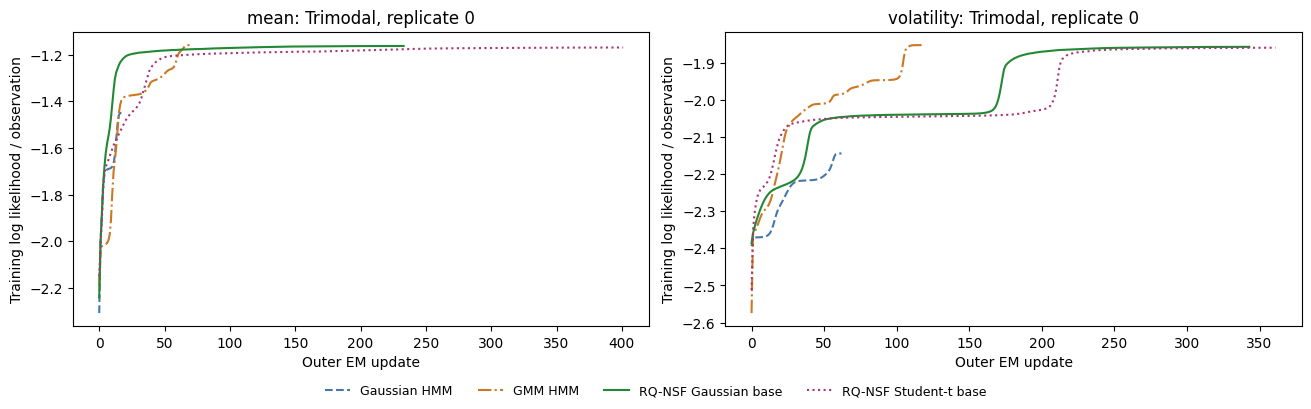

In [29]:
fit_diagnostics = attempts.assign(
    failed=attempts.status.ne("ok"),
    converged_ok=attempts.converged.isin([True, "True", 1])
).groupby(group_columns).agg(
    starts=("status", "size"), failures=("failed", "sum"),
    converged_starts=("converged_ok", "sum"), mean_iterations=("iterations", "mean"),
    summed_fit_seconds=("fit_seconds", "sum"), likelihood_decreases=("likelihood_decreases", "sum")
)
display(save_table(fit_diagnostics, "fit_diagnostics").round(2))
fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
for axis, regime in zip(axes, REGIMES):
    for base, name in implementation.MODEL_NAMES.items():
        selected = selected_attempts[
            (selected_attempts.regime == regime) & (selected_attempts.family == "Trimodal")
            & (selected_attempts.replicate == HISTORY_REPLICATE) & (selected_attempts.model == name)
        ].iloc[0]
        slug = f"{regime}_Trimodal_{int(selected.n_train)}_{HISTORY_REPLICATE}"
        record = reporting.read_json(COMPARISON_DIRECTORY / slug / f"starts_{base}"
                                     / f"start_{int(selected.start)}.json")
        history = np.asarray(record["history"]) / selected.n_train
        axis.plot(np.arange(len(history)), history, label=name,
                  color=experiment.COLORS[name], linestyle=experiment.STYLES[name])
    axis.set(title=f"{regime}: Trimodal, replicate {HISTORY_REPLICATE}",
             xlabel="Outer EM update", ylabel="Training log likelihood / observation")
axes[0].legend()
show_and_save(fig, "selected_training_histories")

### All 100 initializations for one saved dataset

This replaces the old notebook's separate 30-start diagnostic with the actual
100-start budget used here. Histograms show **training** likelihood; dashed
lines mark selected winners. Only winners were evaluated on test data, so no
per-start test F1 or decoded paths are invented for the other 99 starts.

,model,start,seed,selected,status,train_ll,iterations,converged,fit_seconds
240122,GMM HMM,22,2489750391,True,ok,-37025.6643,118,True,36.9926
240145,GMM HMM,45,703310678,False,ok,-37025.6656,185,True,70.7817
240143,GMM HMM,43,4210435733,False,ok,-37025.6661,143,True,50.7080
240131,GMM HMM,31,78690945,False,ok,-37025.6662,120,True,50.7983
240133,GMM HMM,33,3341940842,False,ok,-37025.6664,208,True,77.5293
240065,Gaussian HMM,65,2378730462,True,ok,-42873.7310,62,True,20.9089
240045,Gaussian HMM,45,703310678,False,ok,-42873.7310,53,True,16.9071
240077,Gaussian HMM,77,2587966146,False,ok,-42873.7311,72,True,25.7230
240009,Gaussian HMM,9,3432162280,False,ok,-42873.7311,101,True,35.1086
240099,Gaussian HMM,99,1908685596,False,ok,-42873.7313,54,True,18.6282


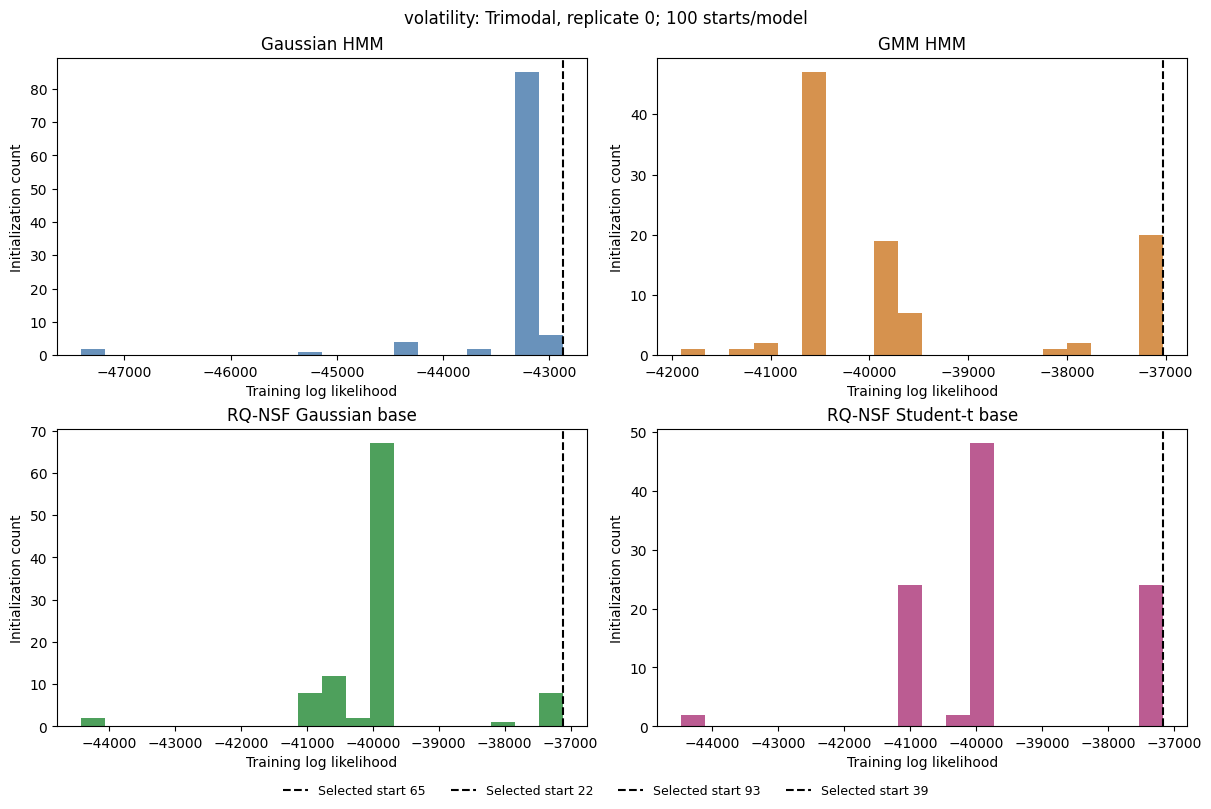

In [30]:
initialization_rows = attempts[
    (attempts.regime == INITIALIZATION_REGIME)
    & (attempts.family == INITIALIZATION_FAMILY)
    & (attempts.replicate == INITIALIZATION_REPLICATE)
].copy()
assert initialization_rows.groupby("model").size().eq(plan["n_starts"]).all()
save_table(initialization_rows, "initialization_diagnostics", index=False)
display(initialization_rows.sort_values(["model", "train_ll"], ascending=[True, False])
        .groupby("model", sort=False).head(5)[
            ["model", "start", "seed", "selected", "status", "train_ll", "iterations", "converged", "fit_seconds"]
        ].round(4))
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
for axis, name in zip(axes.flat, experiment.MODELS):
    part = initialization_rows[initialization_rows.model == name]
    valid = part[part.status.eq("ok") & np.isfinite(part.train_ll)]
    chosen = valid[valid.selected.isin([True, "True", 1])].iloc[0]
    axis.hist(valid.train_ll, bins=20, color=experiment.COLORS[name], alpha=0.8)
    axis.axvline(chosen.train_ll, color="black", linestyle="--",
                 label=f"Selected start {int(chosen.start)}")
    axis.set(title=name, xlabel="Training log likelihood", ylabel="Initialization count")
    axis.legend(fontsize=9)
fig.suptitle(f"{INITIALIZATION_REGIME}: {INITIALIZATION_FAMILY}, replicate {INITIALIZATION_REPLICATE}; 100 starts/model")
show_and_save(fig, "initialization_likelihood_distributions")

### Reference Gaussian KL floor

The Gaussian matching each true state's mean and variance minimizes
$\mathrm{KL}(p_{\rm true}\|q_{\rm Gaussian})$. This population reference explains
the Gaussian emission family's approximation limit; it does not guarantee
that a fitted HMM reaches that limit or aligns its states correctly.

In [31]:
gaussian_floors = experiment.gaussian_floors(sources)
display(save_table(gaussian_floors, "gaussian_kl_floors", index=False).round(7))

,regime,family,state,gaussian_kl_floor,quad_error
0,mean,Gaussian,0,0.000000,0.0
1,mean,Gaussian,1,0.000000,0.0
2,mean,Gaussian,2,0.000000,0.0
3,mean,Student-t,0,0.375897,0.0
4,mean,Student-t,1,0.375897,0.0
5,mean,Student-t,2,0.375897,0.0
6,mean,Trimodal,0,0.259078,0.0
7,mean,Trimodal,1,0.320231,0.0
8,mean,Trimodal,2,0.304501,0.0
9,mean,Skewed Gamma,0,0.088679,0.0


### Representative volatility replicate

Match the previous notebook's descriptive selection rule: across all four
families and models, minimize average distance from median clean F1, emission
KL, transition RMSE, and absolute switch-count error, scaled by feature IQR.
Use one common replicate for all following panels. This uses test outcomes
for illustration; it is not an unbiased substitute for the 100-replicate
aggregate comparisons above.

In [32]:
representative_replicate, representative_scores = reporting.representative_volatility(results, experiment)
if representative_replicate is None:
    raise ValueError("No complete representative volatility replicate")
save_table(representative_scores, "representative_volatility_scores", index=False)
representative_selection = pd.DataFrame([{
    "replicate": representative_replicate, "complete_replicates": len(representative_scores),
    "method": "median distance across all families and models"
}])
display(save_table(representative_selection, "representative_volatility_replicate", index=False))
display(representative_scores.sort_values("representativeness_score").head(10).round(5))

,replicate,complete_replicates,method
0,51,100,median distance across all families and models


,replicate,representativeness_score
51,51,0.25953
57,57,0.33119
39,39,0.36432
25,25,0.39067
96,96,0.39982
54,54,0.40310
41,41,0.40972
69,69,0.42317
62,62,0.43586
9,9,0.43726


#### Representative volatility: true and fitted flow densities

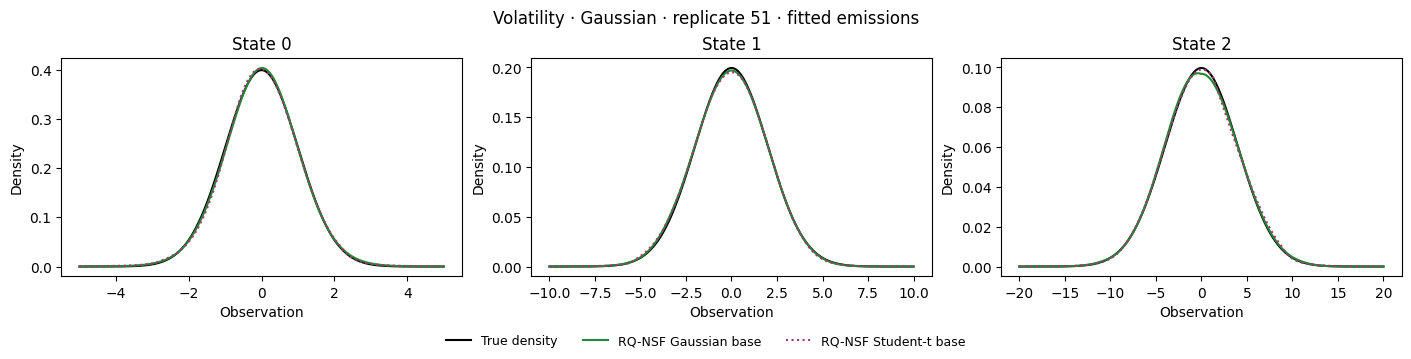

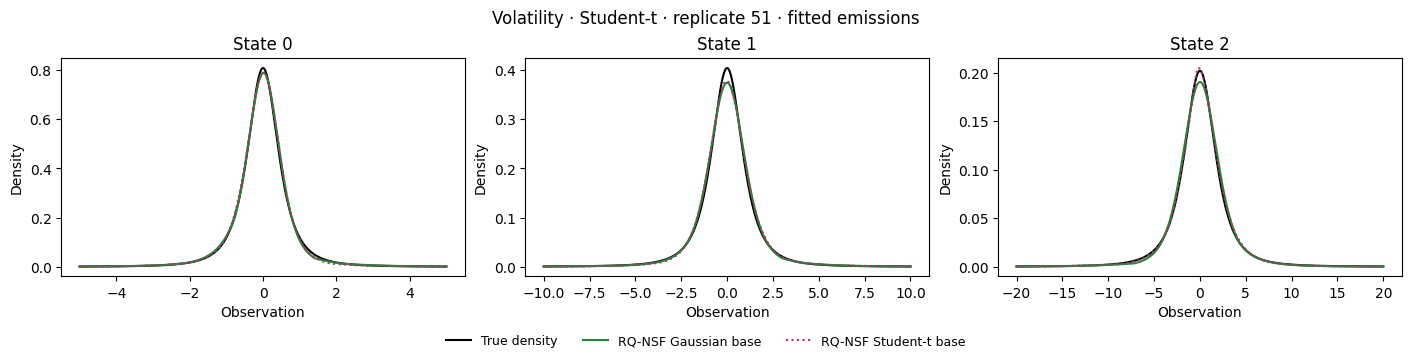

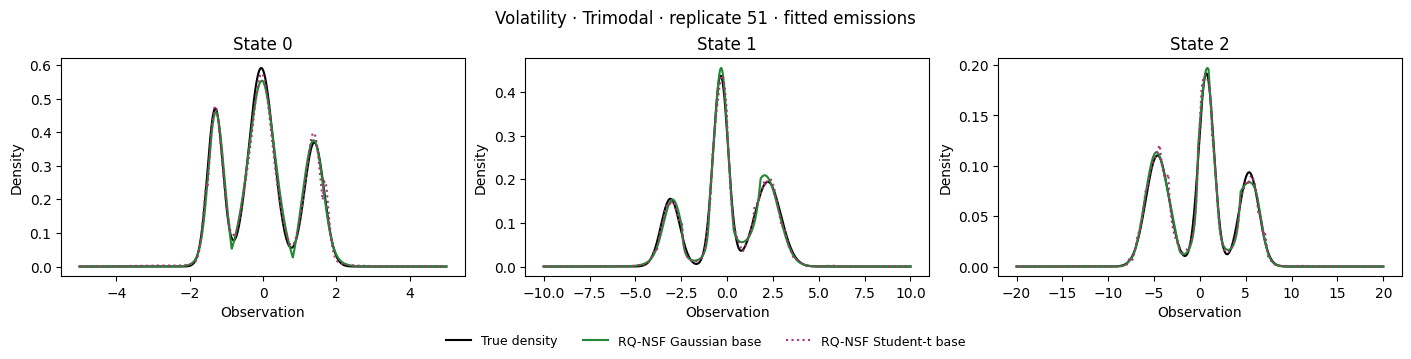

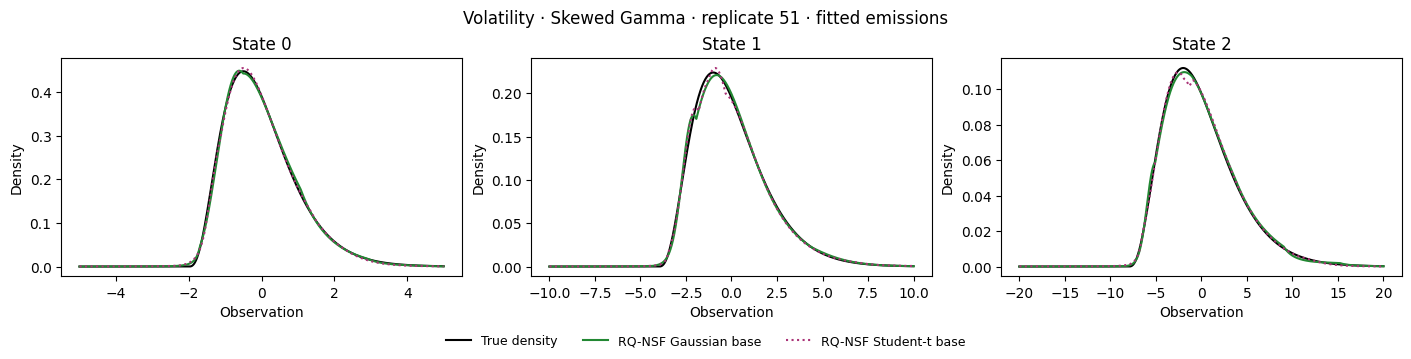

In [33]:
with saved.emission_plot_adapter():
    for family in EXAMPLE_FAMILIES:
        show_and_save(experiment.plot_emissions(
            sources["volatility"], COMPARISON_DIRECTORY, family, flow_only=True,
            replicate=representative_replicate
        ), f"volatility_{family}_replicate_{representative_replicate}_representative_flow_emissions")

#### Representative volatility: decoded state paths

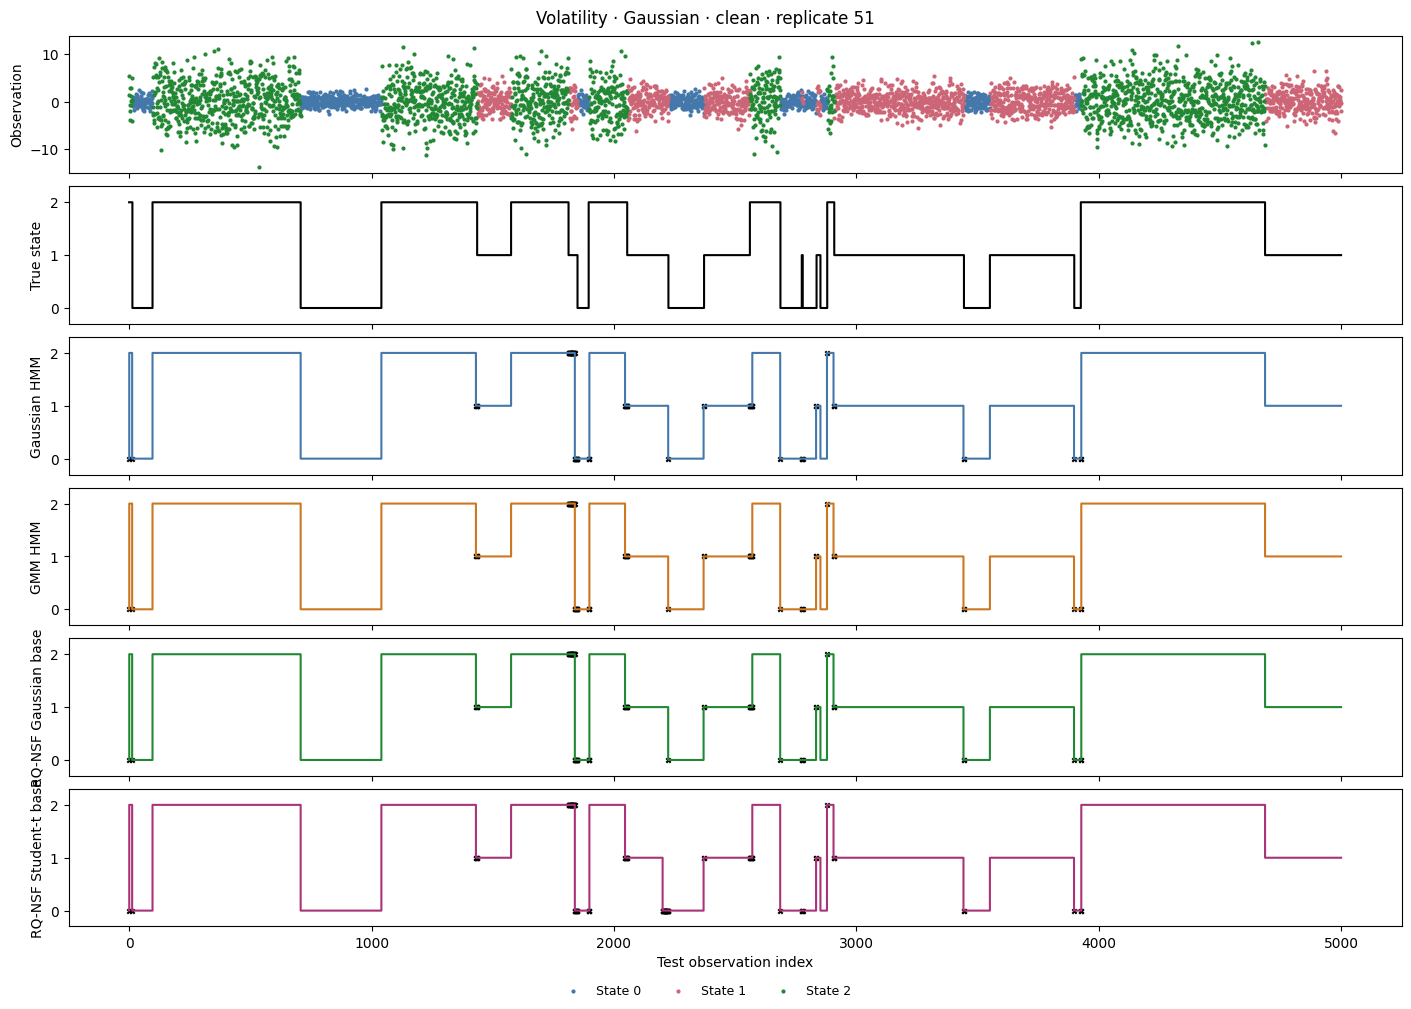

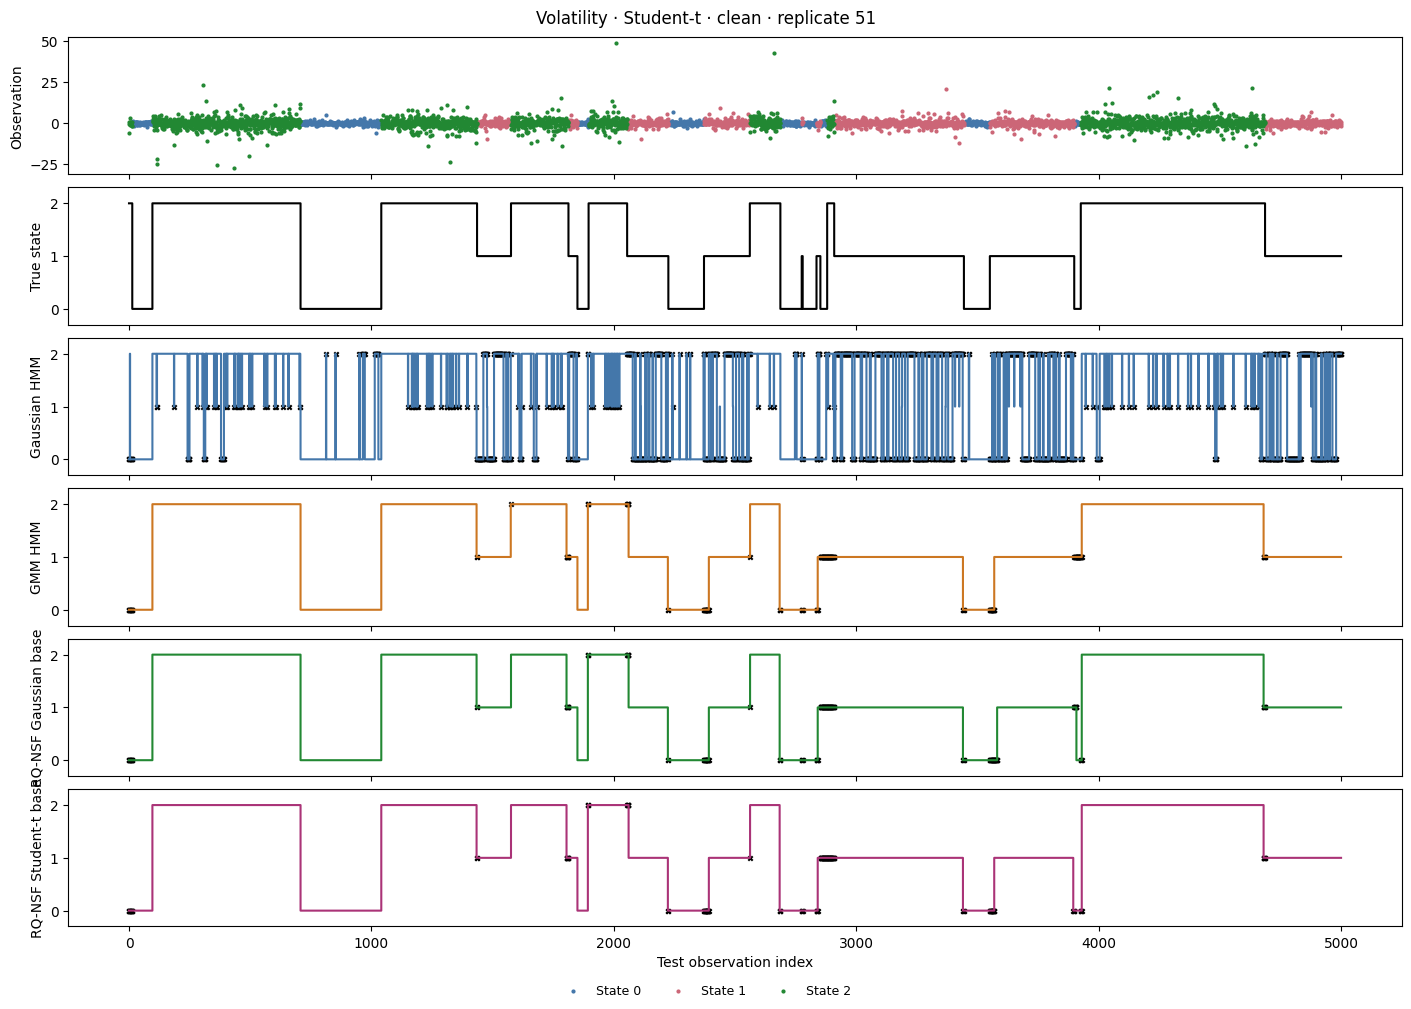

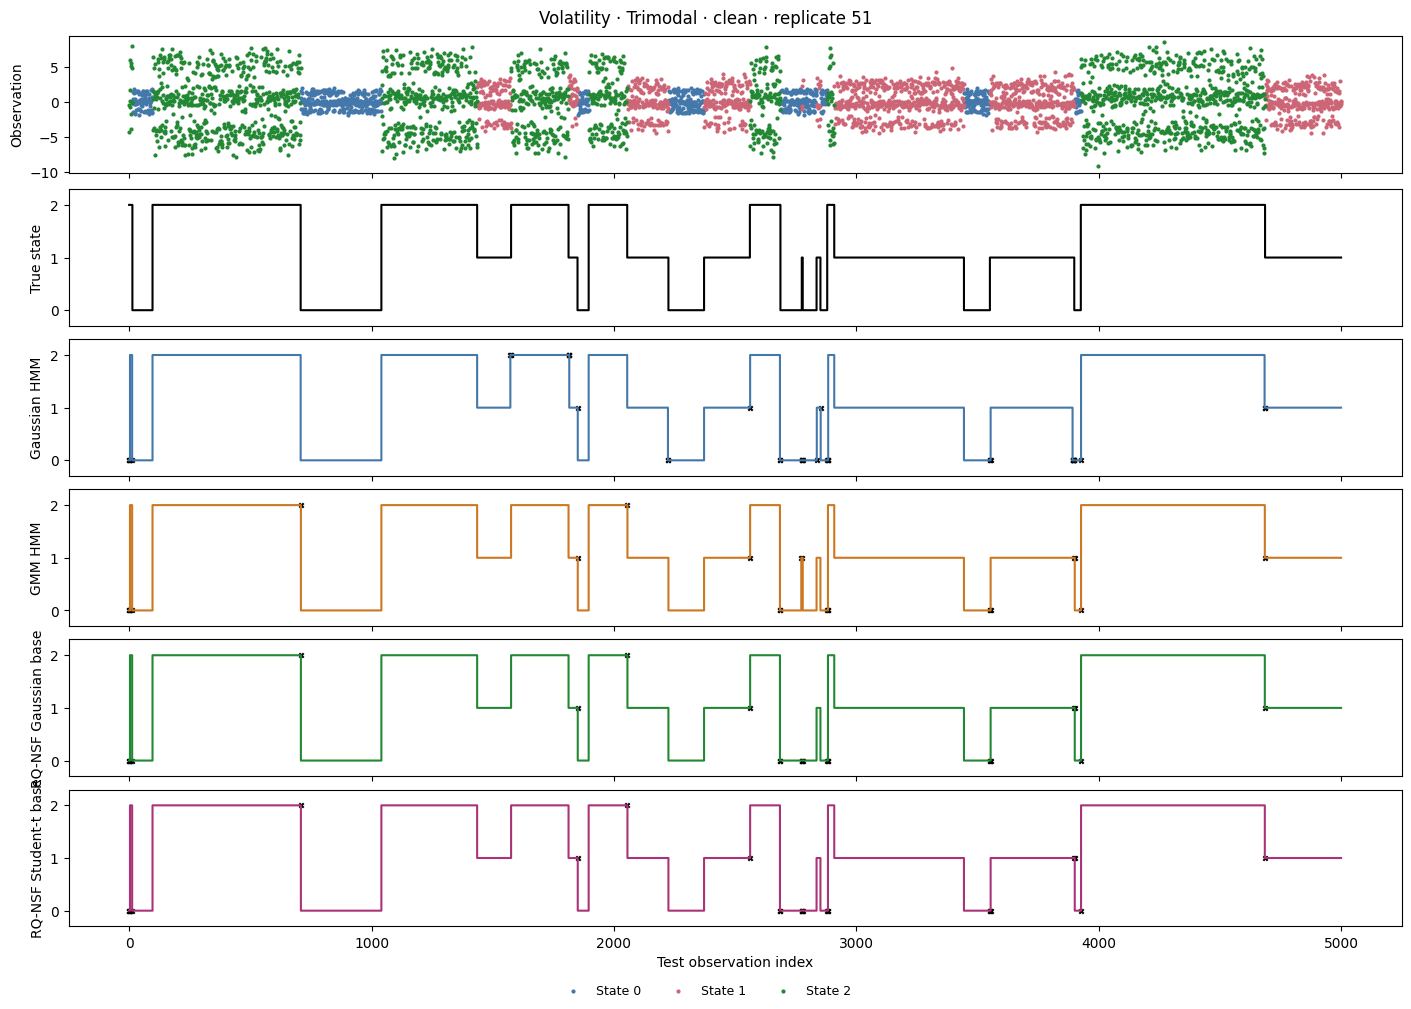

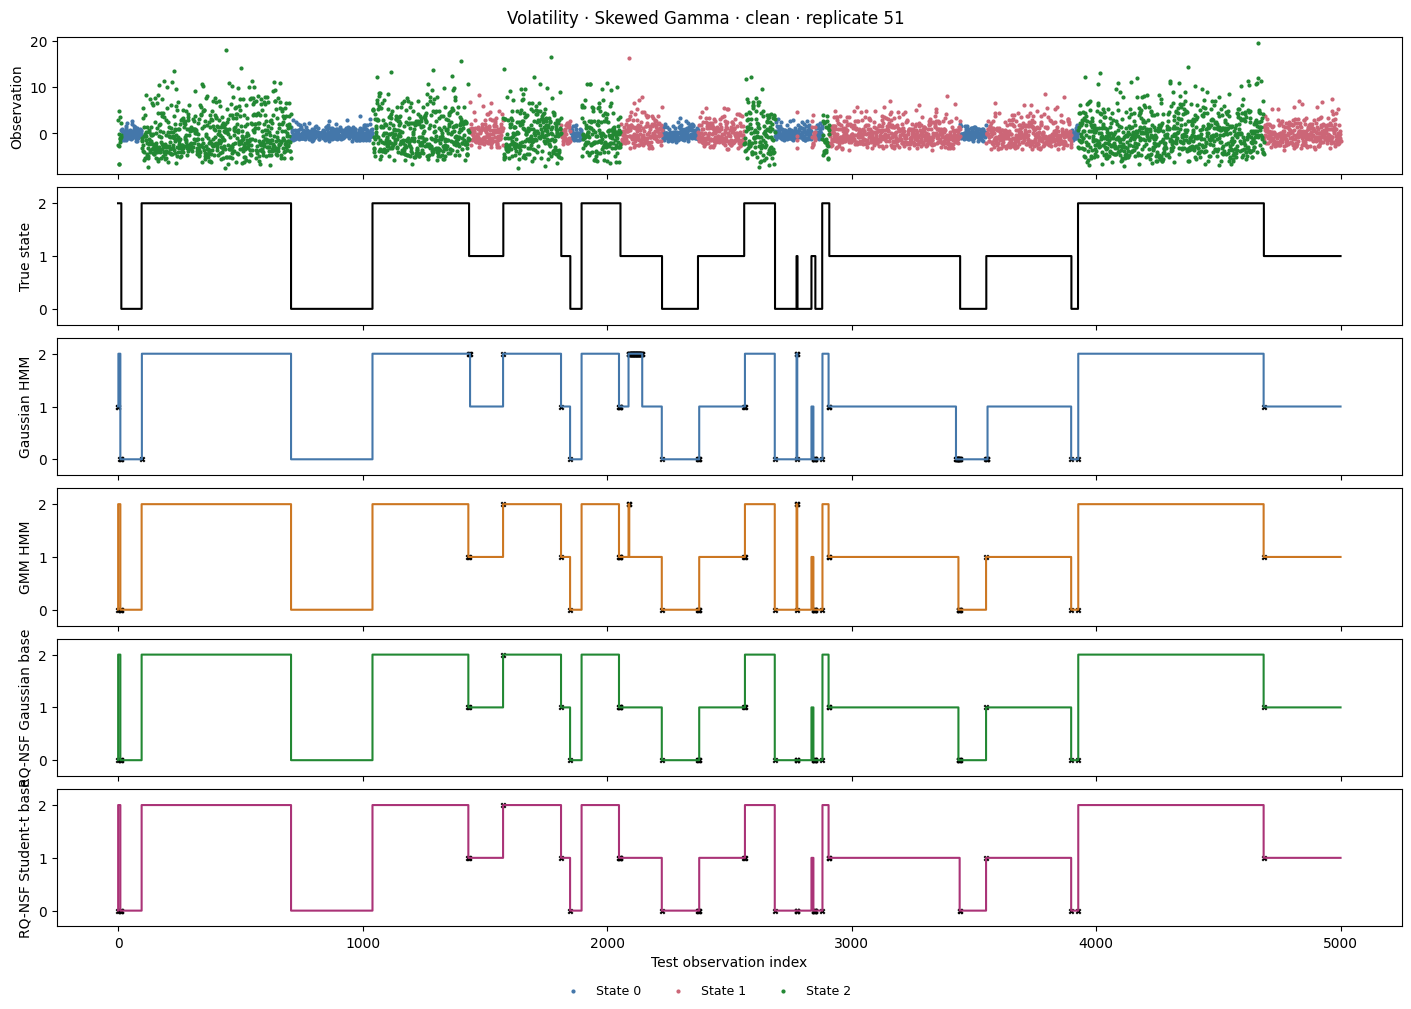

In [34]:
for family in EXAMPLE_FAMILIES:
    show_and_save(saved.plot_decoding(
        sources["volatility"], family, "clean", representative_replicate, DECODED_POINTS
    ), f"volatility_{family}_replicate_{representative_replicate}_representative_decoded_paths")

## Takeaways and saved outputs

Use the aggregate panels and paired intervals for comparisons, with the
density and decoded-path examples explaining behavior on particular datasets.
Differences between families or regimes need not rank models in the same order.
All plots use the repaired recovery results, and all 100 replicates remain in
each comparison. Standalone PNGs and CSVs are exported below, while the notebook
retains its rendered outputs for reopening without rerunning.

In [35]:
overview = clean.groupby(["regime", "family", "model"])[
    ["f1_macro", "test_nll", "emission_kl"]
].mean().unstack("model").round(5)
display(overview)
assert all(reporting.digest(COMPARISON_DIRECTORY / relative) == expected_hash
           for relative, expected_hash in input_hashes.items()), "Evaluation inputs changed"
provenance = {
    "plan_id": plan["id"], "notebook": "notebooks/synthetic_full_experiment.ipynb",
    "generated_at": datetime.now(timezone.utc).isoformat(),
    "input_directory": str(COMPARISON_DIRECTORY), "input_hashes": input_hashes,
    "plan_hash": reporting.digest(plan_path),
    "plotting_implementation_hash": reporting.digest(project_root / "notebooks/nf_hmmlearn_comparison.py"),
    "reporting_adapter_hash": reporting.digest(project_root / "scripts/report_hmm_cluster.py"),
    "evaluation_rows": len(results), "fit_attempts": len(attempts),
    "bootstrap_samples": BOOTSTRAP_SAMPLES, "bootstrap_seed": BOOTSTRAP_SEED,
    "emission_density_replicate": EMISSION_DENSITY_REPLICATE,
    "decoded_path_family": DECODED_PATH_FAMILY,
    "decoded_path_replicate": DECODED_PATH_REPLICATE,
    "representative_volatility_replicate": int(representative_replicate),
    "density_repair_method": repair_record["method"] if repair_record else None,
    "figures": figure_files, "tables": table_files,
}
(OUTPUT_DIRECTORY / "notebook_manifest.json").write_text(json.dumps(provenance, indent=2) + "\n")
display(Markdown(
    f"**Complete:** {len(results):,} evaluation rows; {len(attempts):,} fitted starts; "
    f"{len(figure_files)} figures; {len(table_files)} exported tables.\n\n"
    f"**Figures:** `{FIGURE_DIRECTORY}`\n\n**Tables:** `{TABLE_DIRECTORY}`"
))

f1_macro                                    \
model                    GMM HMM Gaussian HMM RQ-NSF Gaussian base   
regime     family                                                    
mean       Gaussian      0.99740      0.99737              0.99741   
           Skewed Gamma  0.99832      0.99681              0.99840   
           Student-t     0.99888      0.97720              0.99874   
           Trimodal      0.99838      0.99716              0.99833   
volatility Gaussian      0.98192      0.98184              0.98184   
           Skewed Gamma  0.98520      0.96100              0.98510   
           Student-t     0.95658      0.49139              0.95674   
           Trimodal      0.99471      0.87034              0.99460   

                                              test_nll               \
model                   RQ-NSF Student-t base  GMM HMM Gaussian HMM   
regime     family                                                     
mean       Gaussian                   0.99738  1.45067      1.45040   
           Skewed Gamma               0.99840  1.36924      1.45033   
           Student-t                  0.99894  1.08304      1.35911   
           Trimodal                   0.99832  1.16057      1.45127   
volatility Gaussian                   0.98103  2.12986      2.12964   
           Skewed Gamma               0.98515  2.05157      2.12843   
           Student-t                  0.95866  1.75497      1.81947   
           Trimodal                   0.99438  1.84393      2.13969   

                                                                    \
model                   RQ-NSF Gaussian base RQ-NSF Student-t base   
regime     family                                                    
mean       Gaussian                  1.45094               1.45386   
           Skewed Gamma              1.36498               1.36667   
           Student-t                 1.08649               1.07968   
           Trimodal                  1.16273               1.16899   
volatility Gaussian                  2.13014               2.13191   
           Skewed Gamma              2.04852               2.04995   
           Student-t                 1.75690               1.75326   
           Trimodal                  1.84888               1.85408   

                        emission_kl                                    \
model                       GMM HMM Gaussian HMM RQ-NSF Gaussian base   
regime     family                                                       
mean       Gaussian         0.00043      0.00015              0.00073   
           Skewed Gamma     0.00691      0.08905              0.00291   
           Student-t        0.00958      0.52015              0.02157   
           Trimodal         0.00062      0.29473              0.00534   
volatility Gaussian         0.00045      0.00016              0.00088   
           Skewed Gamma     0.00693      0.09915              0.00390   
           Student-t        0.01101      1.11683              0.02160   
           Trimodal         0.00063      2.19844              0.00766   

                                               
model                   RQ-NSF Student-t base  
regime     family                              
mean       Gaussian                   0.00377  
           Skewed Gamma               0.00461  
           Student-t                  0.00165  
           Trimodal                   0.01170  
volatility Gaussian                   0.00286  
           Skewed Gamma               0.00550  
           Student-t                  0.00296  
           Trimodal                   0.01291

**Complete:** 12,800 evaluation rows; 320,000 fitted starts; 45 figures; 15 exported tables.

**Figures:** `/Users/leoyang/Desktop/School/CSCD94/cluster_runs/hmm_100x100/comparison/synthetic_full_experiment/figures`

**Tables:** `/Users/leoyang/Desktop/School/CSCD94/cluster_runs/hmm_100x100/comparison/synthetic_full_experiment/tables`